# Comparing results through declared correspondences

A new coefficient field, a finer grid, or a different homology degree can change a figure. Before interpreting that change, we need to say which queries correspond. This guide builds comparisons from that declaration, then inspects dimensions, ranks and ordinary barcodes on shared scales. A second branch compares collections through named features, supplied distances and optional embeddings.

You should be comfortable with [spaces and maps](../spaces_and_maps.md). The [finite-encoding lesson](../finite_encodings.md) supplies the language for the grid example. Our first object is just one linear map, so no point-cloud construction is needed.

We will separate three questions: did the observable change, did only the basis change, or did we change the query itself? The [visualization reference](../src/reference/visualization.md) gives the full API contracts; [the implementation account](../implementation/visual_specs.md) explains preparation and reuse.

If you already have feature or distance tables for several samples, you can begin at [Compare samples through named features](#compare-samples-through-named-features).

In [1]:
import TamerOp as OP
import CairoMakie
using SparseArrays: sparse

P = OP.Advanced.FinitePoset(BitMatrix([true true; false true]))
F2, F3 = OP.CoreModules.F2(), OP.CoreModules.F3()
K2, K3 = OP.CoreModules.coeff_type(F2), OP.CoreModules.coeff_type(F3)
M2 = OP.Advanced.PModule{K2}(P, [2,2], Dict((1,2) => K2[1 1; 1 -1]); field=F2)
M3 = OP.Advanced.PModule{K3}(P, [2,2], Dict((1,2) => K3[1 1; 1 -1]); field=F3);

PModule
  field: F3
  vertices: 2
  total dimension: 4
  max stalk dimension: 2
  edge count: 1
  poset type: FinitePoset

## Change the field, keep the question

Both modules have two-dimensional spaces at source and target. Their map comes from the integer matrix

$$A=\begin{pmatrix}1&1\\1&-1\end{pmatrix}.$$

Over $\mathbf F_2$, the two columns agree. Over $\mathbf F_3$, the determinant $-2$ is nonzero. Predict the ranks before looking at the second figure.

`ComparisonCase` attaches the modeling context to each result. The field comes from the result itself. Here there is no homology grading: the spaces are a direct algebraic input. Each list in `vertices` identifies the corresponding source and target explicitly. Equal label numbers alone would not supply that identification.

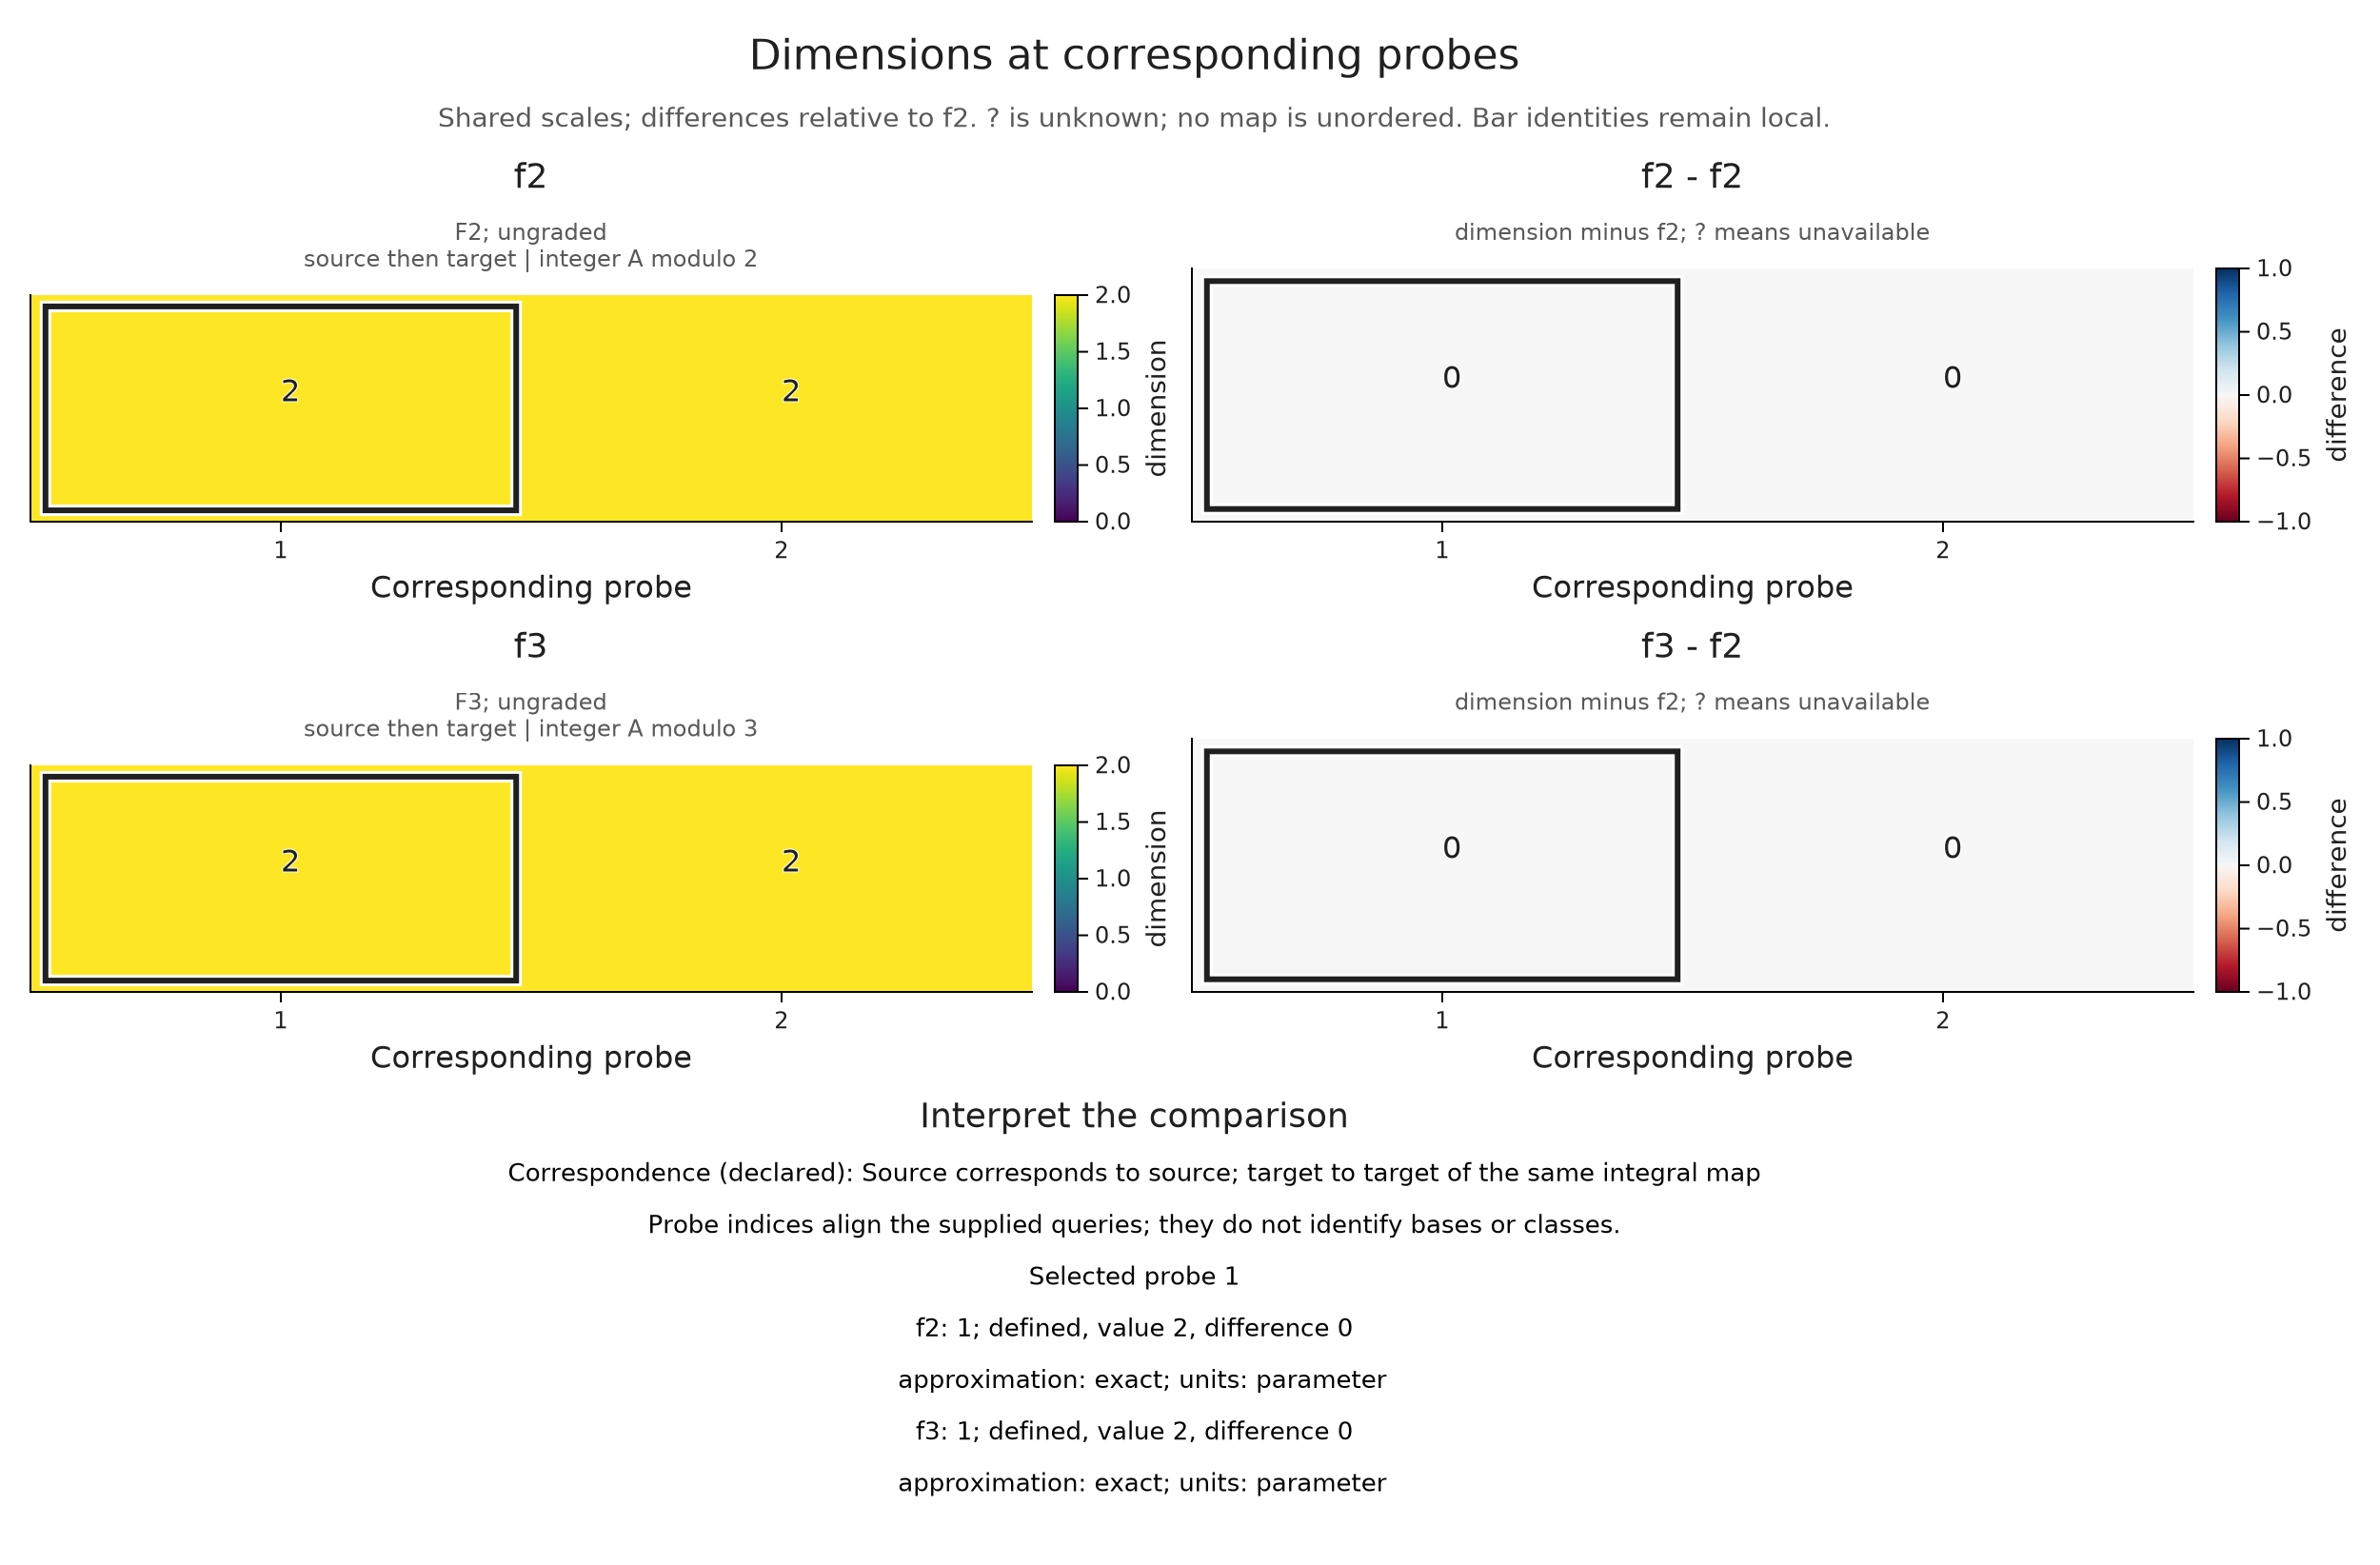

In [2]:
fields = OP.compare_visuals((
    f2 = OP.ComparisonCase(M2; filtration="source then target", construction="integer A modulo 2", approximation="exact"),
    f3 = OP.ComparisonCase(M3; filtration="source then target", construction="integer A modulo 3", approximation="exact"));
    vertices=(f2=[1,2], f3=[1,2]),
    correspondence="Source corresponds to source; target to target of the same integral map")
OP.visualize(fields)

The horizontal axis lists **probe indices**, not a continuous parameter. The left column gives the observable; the right column subtracts the selected baseline. Exact numbers keep the comparison readable without relying on color.

Dimensions miss the change in $A$. Select `view=:rank` to ask for ranks from one fixed source to every probe. The source defaults to probe 1. The identity map at the source has rank 2 in both cases; the map to probe 2 has ranks 1 and 2.

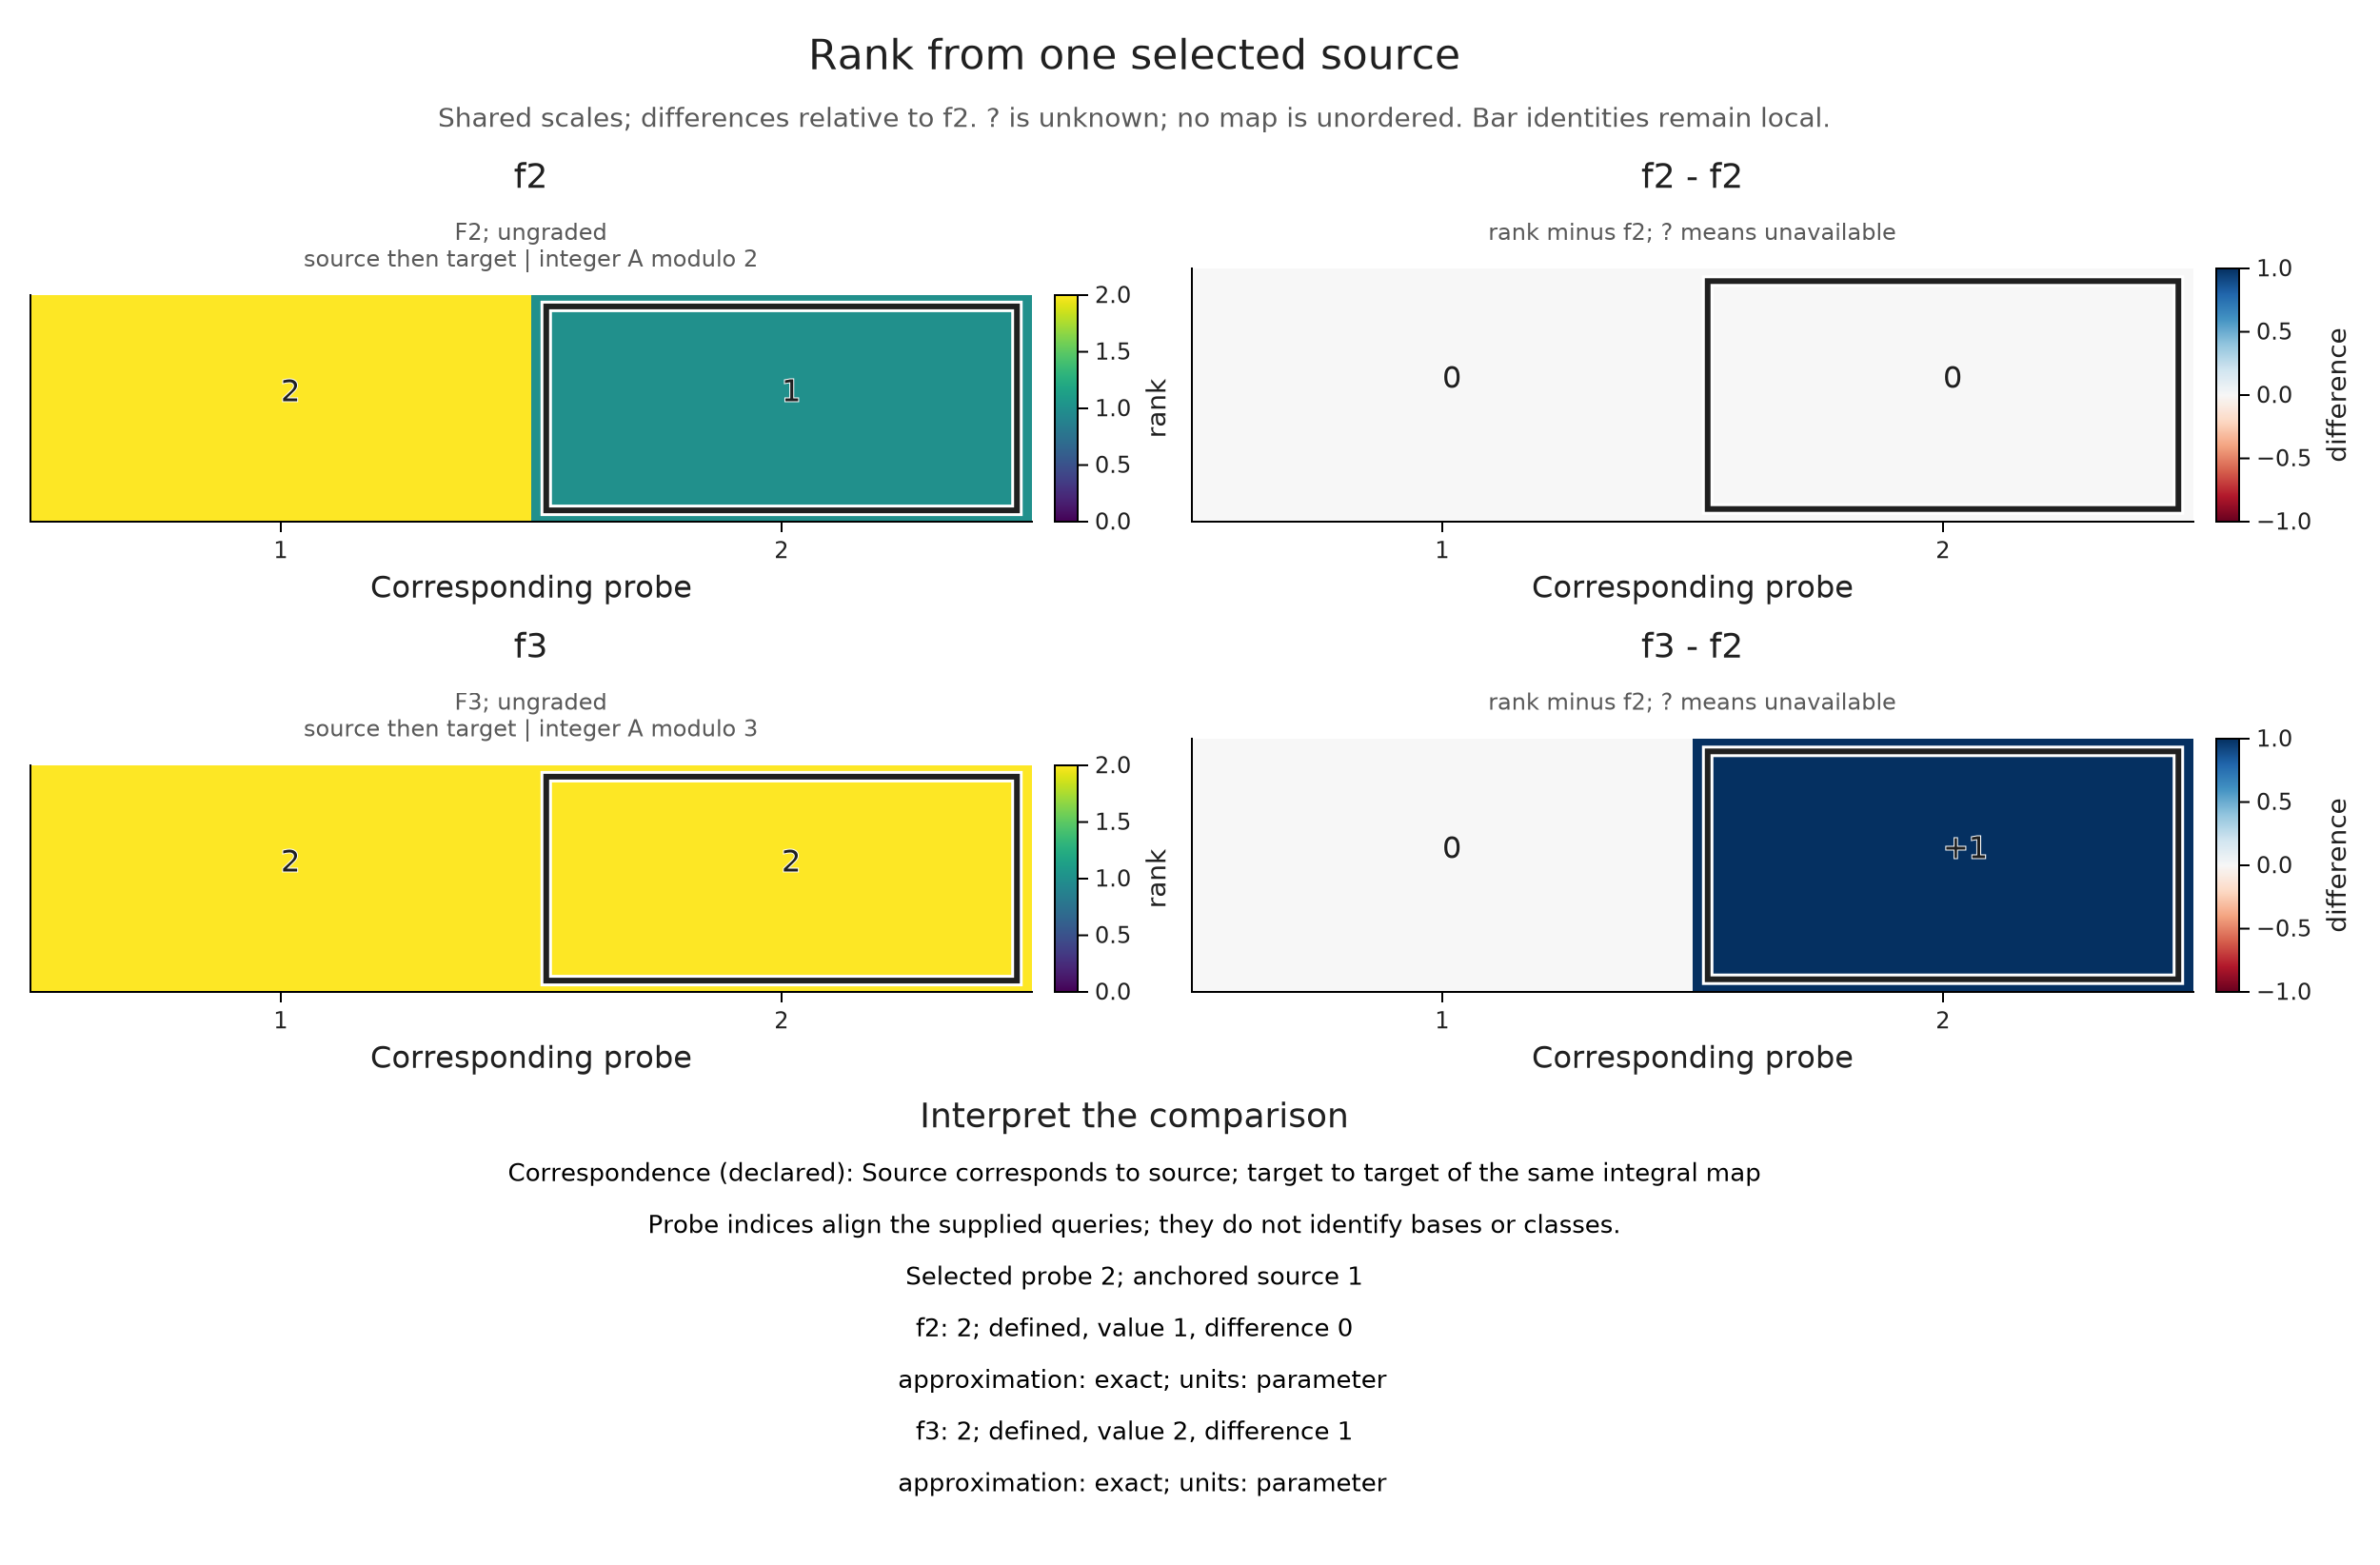

In [3]:
rank_view = OP.Advanced.visual_spec(fields; view=:rank, probe=2)
@assert [v.value for v in rank_view.metadata.values.f2] == [2,1]
@assert [v.value for v in rank_view.metadata.values.f3] == [2,2]
OP.visualize(rank_view)

## Change coordinates, preserve the map

A nonzero difference between matrix entries need not mean that a map changed. Over $\mathbf Q$, take $A=\left(\begin{smallmatrix}1&0\\0&0\end{smallmatrix}\right)$ and $B=\left(\begin{smallmatrix}1&-1\\1&-1\end{smallmatrix}\right)$. The invertible source and target changes below satisfy $BS=TA$. Thus they describe isomorphic representations of our two-vertex poset.

We check that equation ourselves. The comparison viewer reports observable differences; it does not turn the correspondence description into an isomorphism certificate.

In [4]:
A = OP.QQ[1 0; 0 0]
B = OP.QQ[1 -1; 1 -1]
S = OP.QQ[1 1; 0 1]
T = OP.QQ[1 0; 1 1]
@assert B*S == T*A
original = OP.Advanced.PModule{OP.QQ}(P, [2,2], Dict((1,2)=>A); field=OP.CoreModules.QQField())
changed = OP.Advanced.PModule{OP.QQ}(P, [2,2], Dict((1,2)=>B); field=OP.CoreModules.QQField());

PModule
  field: QQ
  vertices: 2
  total dimension: 4
  max stalk dimension: 2
  edge count: 1
  poset type: FinitePoset

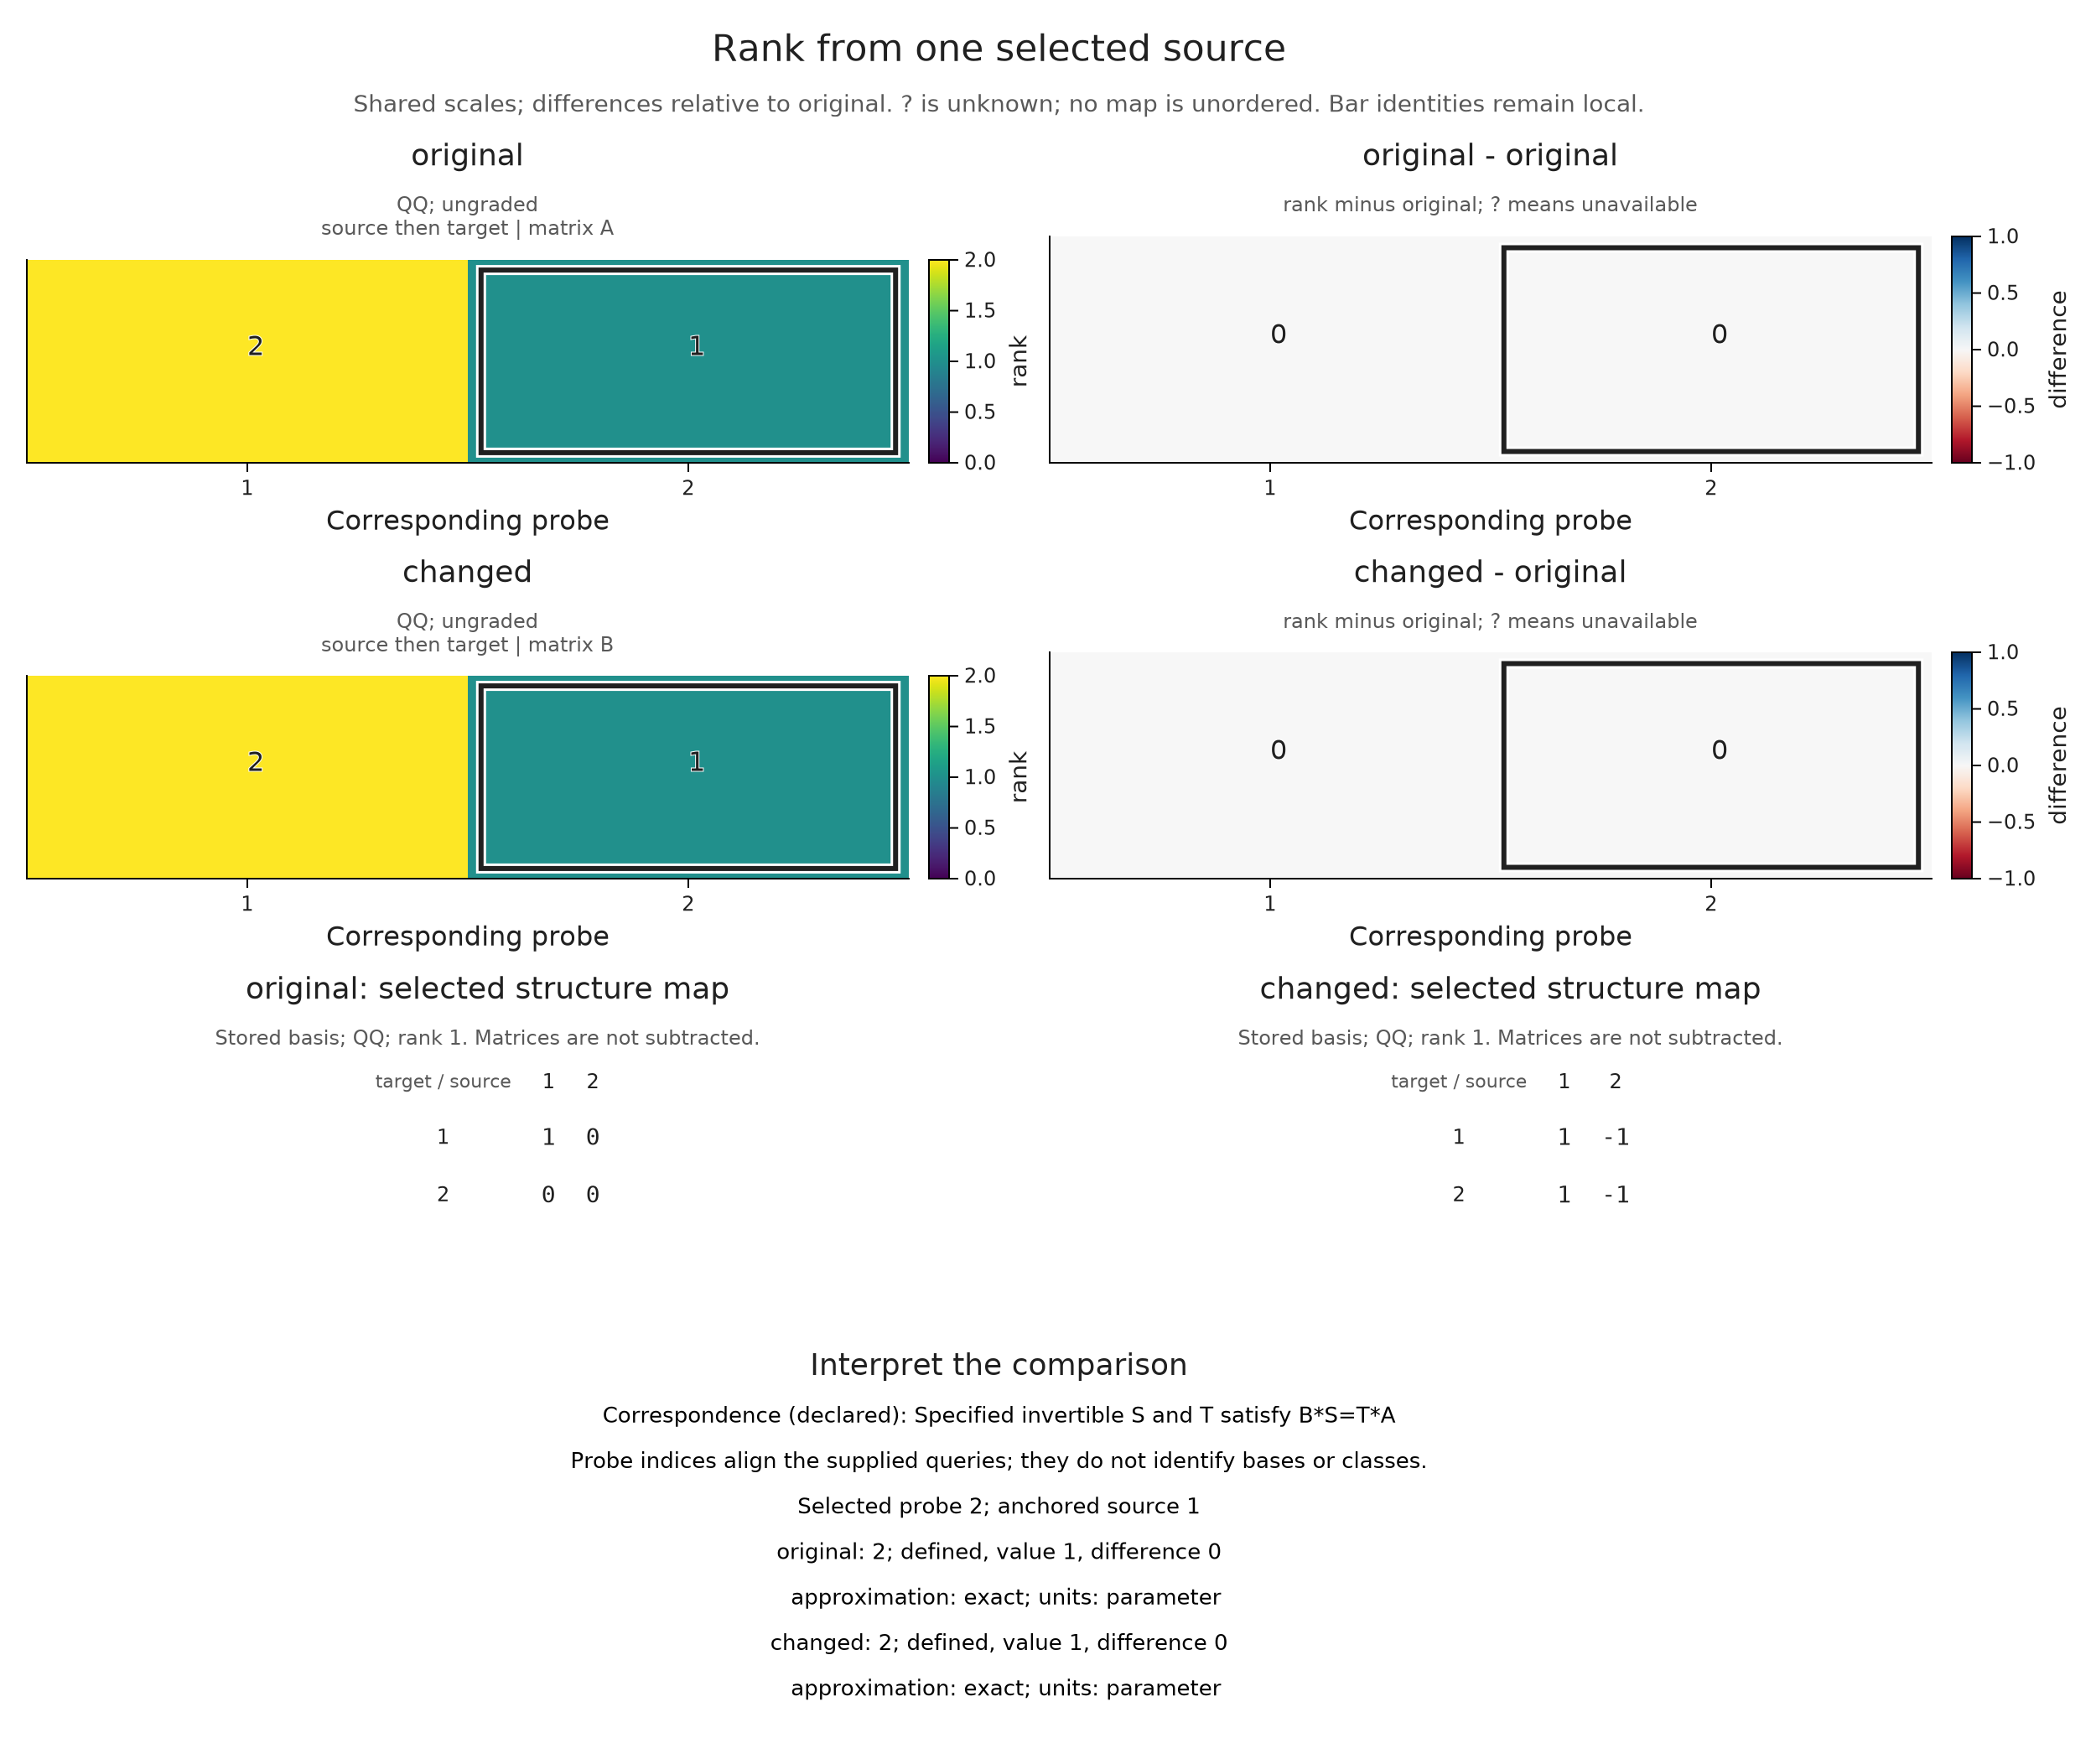

In [5]:
bases = OP.compare_visuals((
    original=OP.ComparisonCase(original; filtration="source then target", construction="matrix A", approximation="exact"),
    changed=OP.ComparisonCase(changed; filtration="source then target", construction="matrix B", approximation="exact"));
    vertices=(original=[1,2], changed=[1,2]), correspondence="Specified invertible S and T satisfy B*S=T*A")
OP.visualize(bases; view=:rank, probe=2, matrix=true)

## Change the finite description, preserve the parameters

Now use the square-supported module on the nonnegative plane: it is one-dimensional on $[0,2)\times[0,2)$ and zero elsewhere in that domain. A coarse grid and a grid subdivided at 1 describe the same module. Their finite label sets differ, so comparing vertex 2 with vertex 2 would ask different questions.

We declare shared **original parameter points**. Each classifier locates those points independently. The point below zero is outside both encodings; `?` records unavailable data, rather than an inferred zero stalk.

In [6]:
coarse_poset = OP.Advanced.ProductOfChainsPoset((2,2))
fine_poset = OP.Advanced.ProductOfChainsPoset((3,3))
coarse_dims = [1,0,0,0]
fine_dims = [1,1,0,1,1,0,0,0,0]
coarse_module = OP.Advanced.PModule{OP.QQ}(coarse_poset, coarse_dims,
    Dict((a,b)=>ones(OP.QQ,coarse_dims[b],coarse_dims[a]) for (a,b) in OP.Advanced.cover_edges(coarse_poset)))
fine_module = OP.Advanced.PModule{OP.QQ}(fine_poset, fine_dims,
    Dict((a,b)=>ones(OP.QQ,fine_dims[b],fine_dims[a]) for (a,b) in OP.Advanced.cover_edges(fine_poset)))
coarse = OP.EncodingResult(coarse_poset, coarse_module,
    OP.Advanced.GridEncodingMap(coarse_poset, ([0,2],[0,2])))
fine = OP.EncodingResult(fine_poset, fine_module,
    OP.Advanced.GridEncodingMap(fine_poset, ([0,1,2],[0,1,2])));

EncodingResult
  poset_type: TamerOp.FiniteFringe.ProductOfChainsPoset{2}
  module_type: TamerOp.Modules.PModule{Rational{BigInt}, TamerOp.CoreModules.CoeffFields.QQField, Matrix{Rational{BigInt}}, TamerOp.FiniteFringe.ProductOfChainsPoset{2}}
  encoding_map_type: TamerOp.EncodingCore.GridEncodingMap{2, Int64, TamerOp.FiniteFringe.ProductOfChainsPoset{2}}
  backend: auto
  compiled: false
  has_cohomology: false
  has_presentation: false
  materialized: true
  module_dims: [1, 1, 0, 1, 1, 0, 0, 0, 0]
  category: finite_poset_representations
  field: TamerOp.CoreModules.CoeffFields.QQField()
  degree: nothing (not_applicable)
  window: not_recorded
  orientation: not_recorded
  construction: (requested = :not_recorded, effective = :not_recorded, substitution = :not_recorded)
  discretization: not_recorded
  approximation: not_recorded

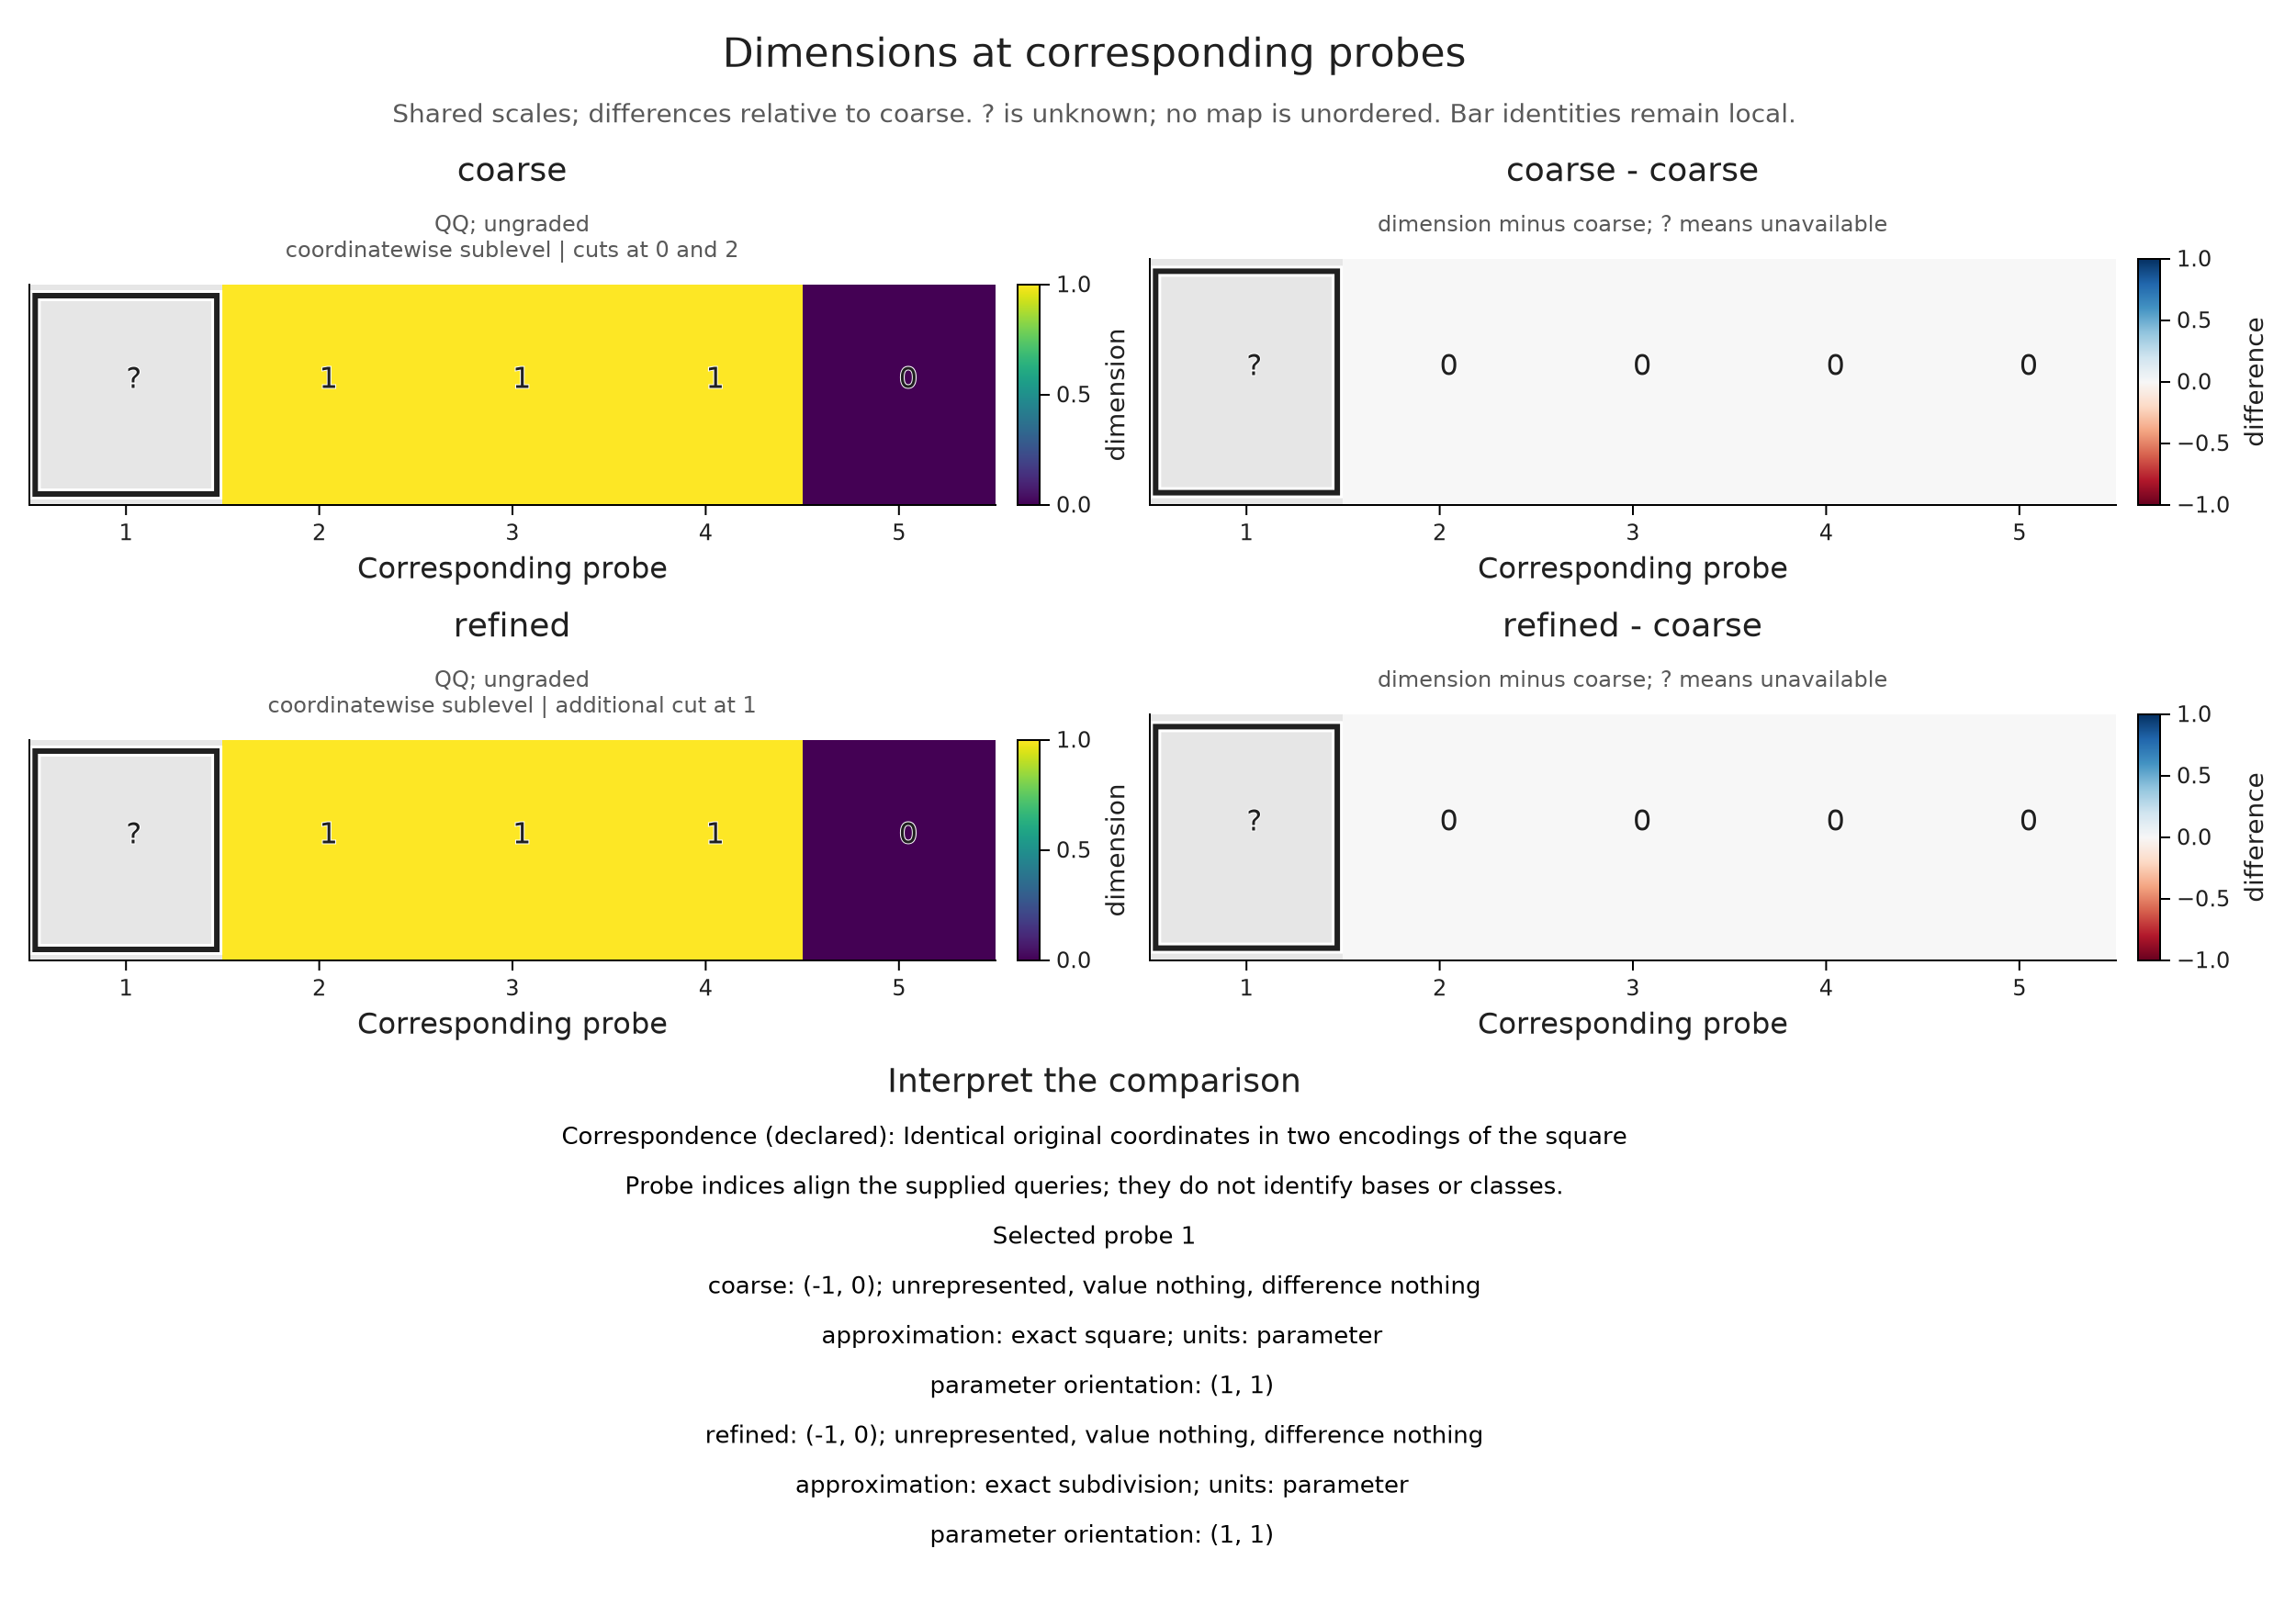

In [7]:
points = [(-1,0), (0,0), (1//2,1//2), (3//2,3//2), (2,2)]
grids = OP.compare_visuals((
    coarse=OP.ComparisonCase(coarse; filtration="coordinatewise sublevel", construction="cuts at 0 and 2", approximation="exact square"),
    refined=OP.ComparisonCase(fine; filtration="coordinatewise sublevel", construction="additional cut at 1", approximation="exact subdivision"));
    points, correspondence="Identical original coordinates in two encodings of the square")
OP.visualize(grids)

Agreement at these probes is evidence about these queries. To inspect an actual comparison map on a common refinement, continue to [refining and transporting encoded modules](compare_encodings.ipynb).

A discretization can instead change the parameter we ask about. Here the declared sampling rule rounds $(3/2,3/2)$ upward to $(2,2)$. It crosses the square's open upper boundary, so the dimension falls from 1 to 0. Supplying separate point lists makes this change explicit. The word “approximation” in the context is a description; it is not a certified error bound.

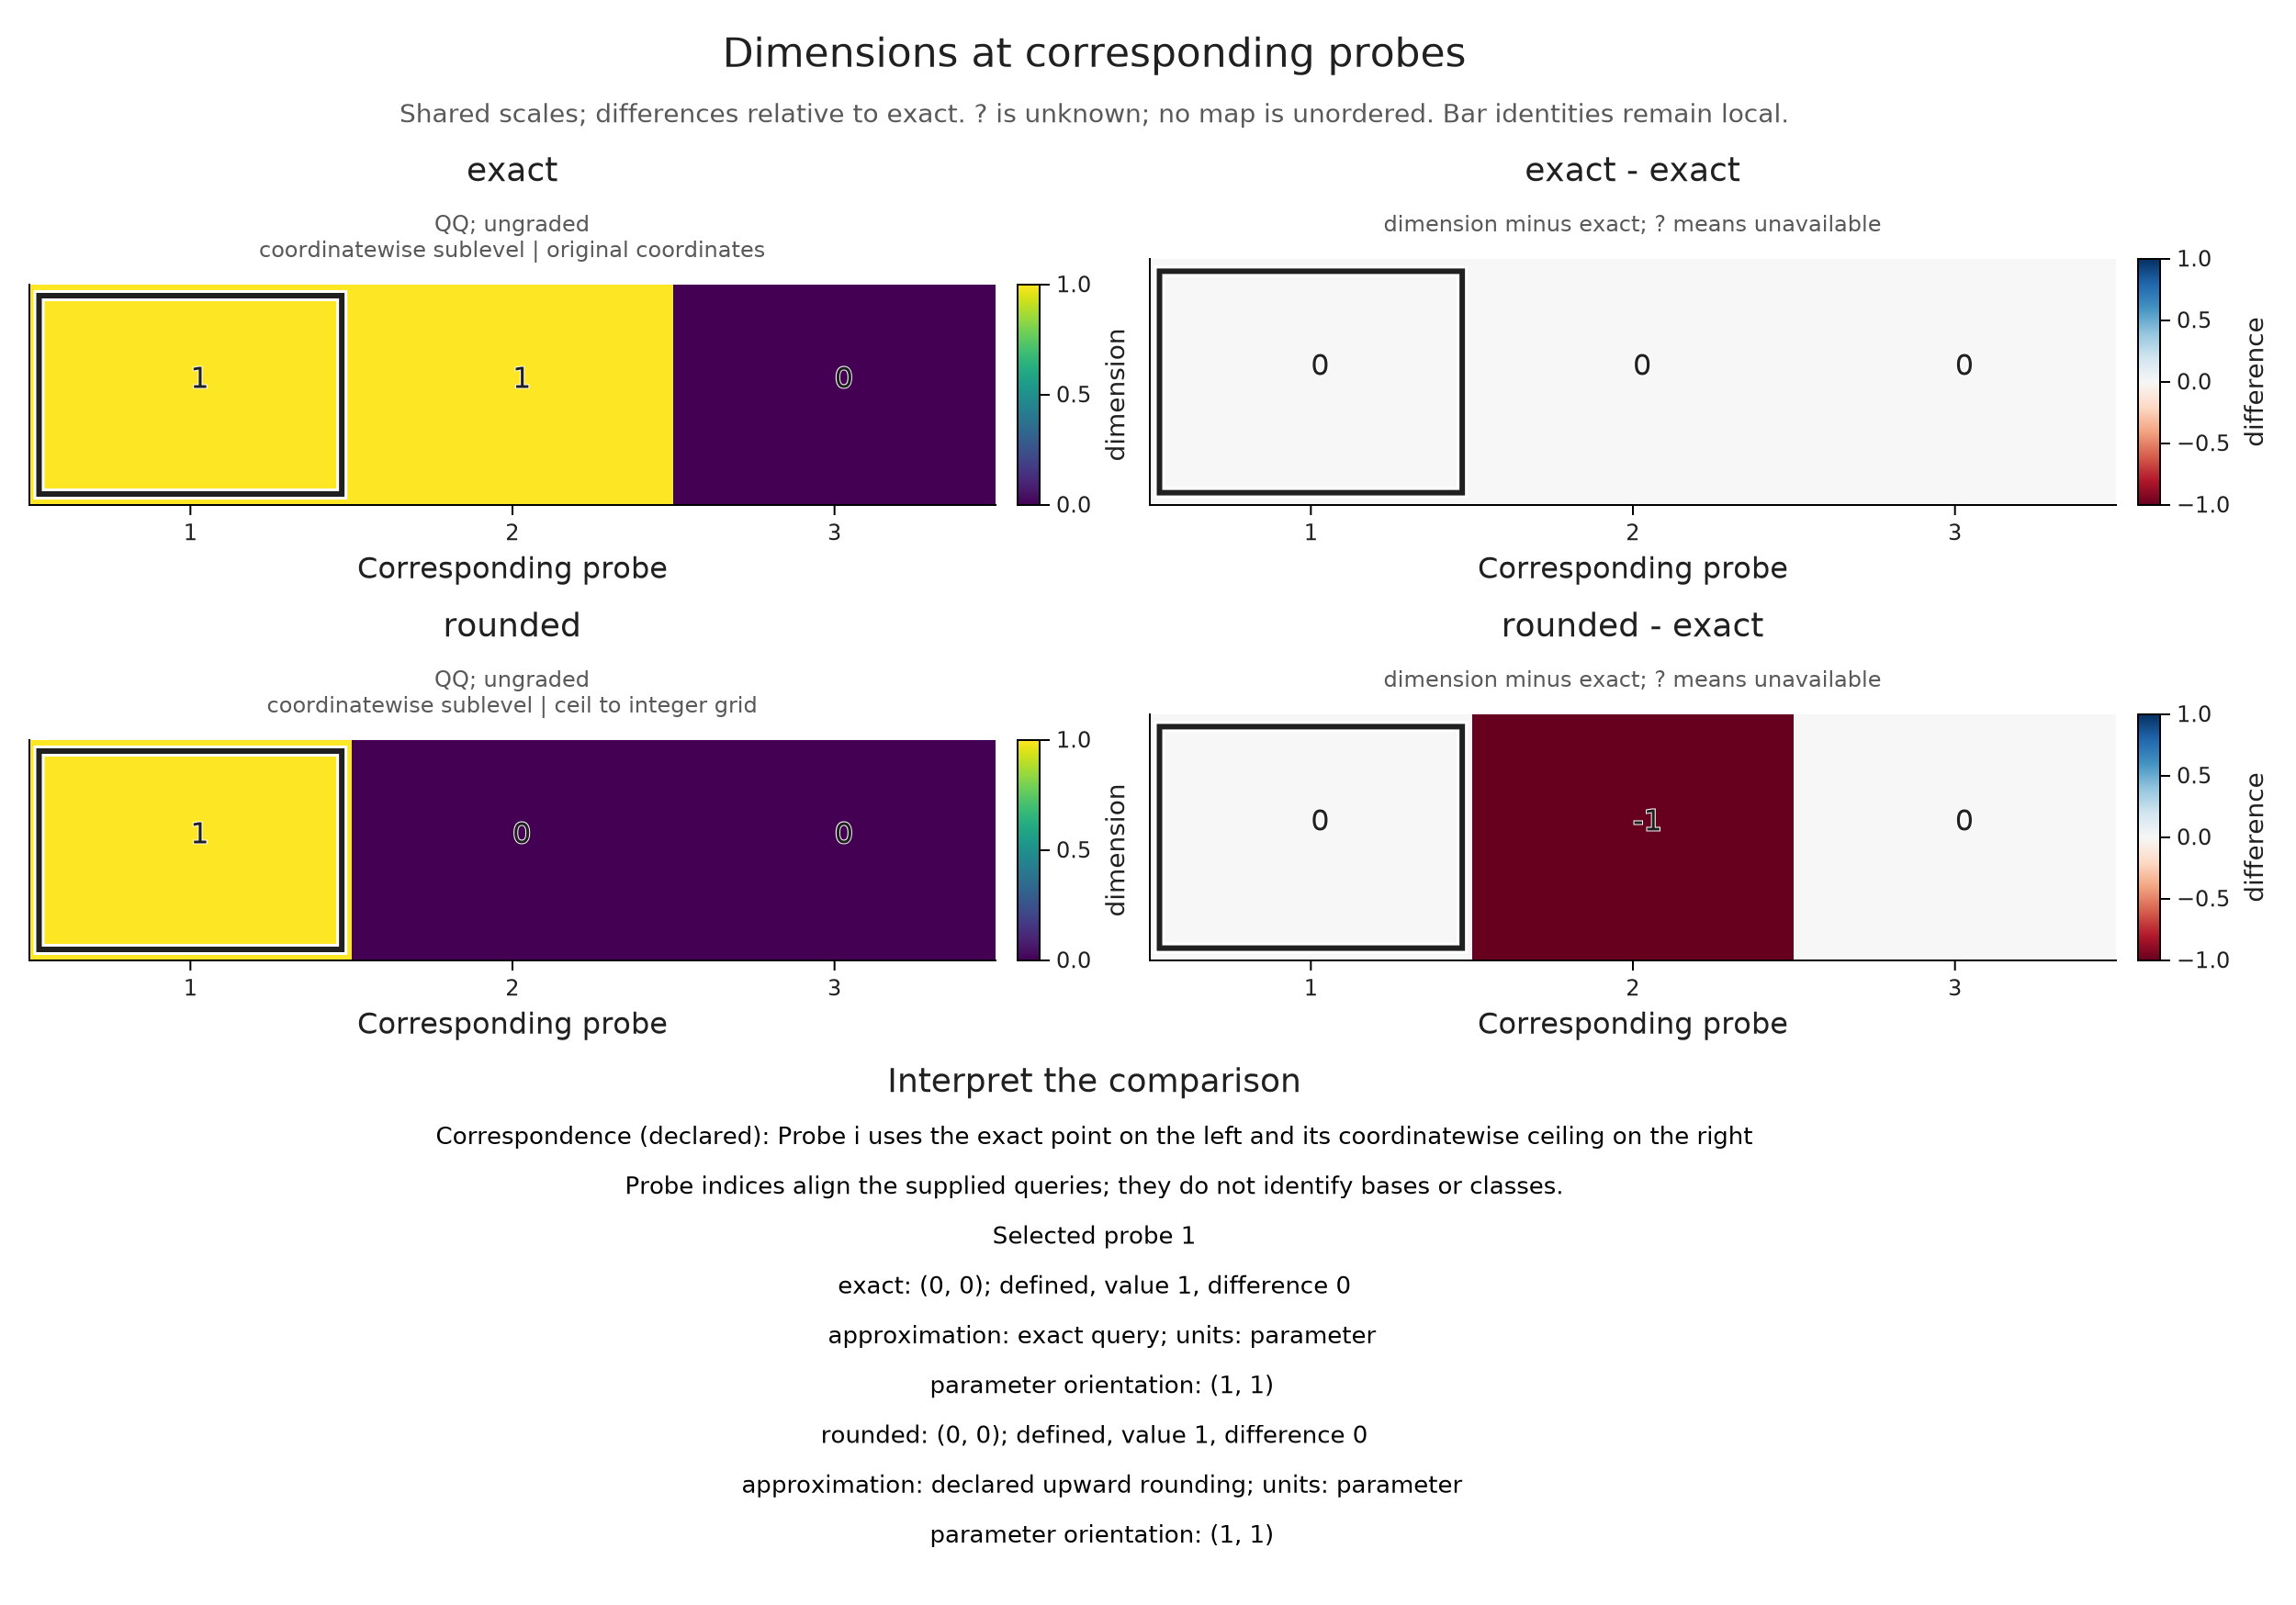

In [8]:
rounded = OP.compare_visuals((
    exact=OP.ComparisonCase(coarse; filtration="coordinatewise sublevel", construction="original coordinates", approximation="exact query"),
    rounded=OP.ComparisonCase(coarse; filtration="coordinatewise sublevel", construction="ceil to integer grid", approximation="declared upward rounding"));
    points=(exact=[(0,0),(3//2,3//2),(2,2)], rounded=[(0,0),(2,2),(2,2)]),
    correspondence="Probe i uses the exact point on the left and its coordinatewise ceiling on the right")
OP.visualize(rounded)

## Compare barcodes in the same parameter units

For an ordinary persistence result we can also display its intervals. Consider an integral filtered chain complex with one generator in degree 0, appearing at 0, and one in degree 1, appearing at 1. The differential multiplies by 2. Over $\mathbf F_2$ it vanishes; over $\mathbf F_3$ it kills the degree-zero class at 1.

The parameter lists are shared, and `degree=0` selects what is being compared. At the death parameter, the finite interval is already absent. Essential bars remain distinguished from finite intervals clipped by the display window.

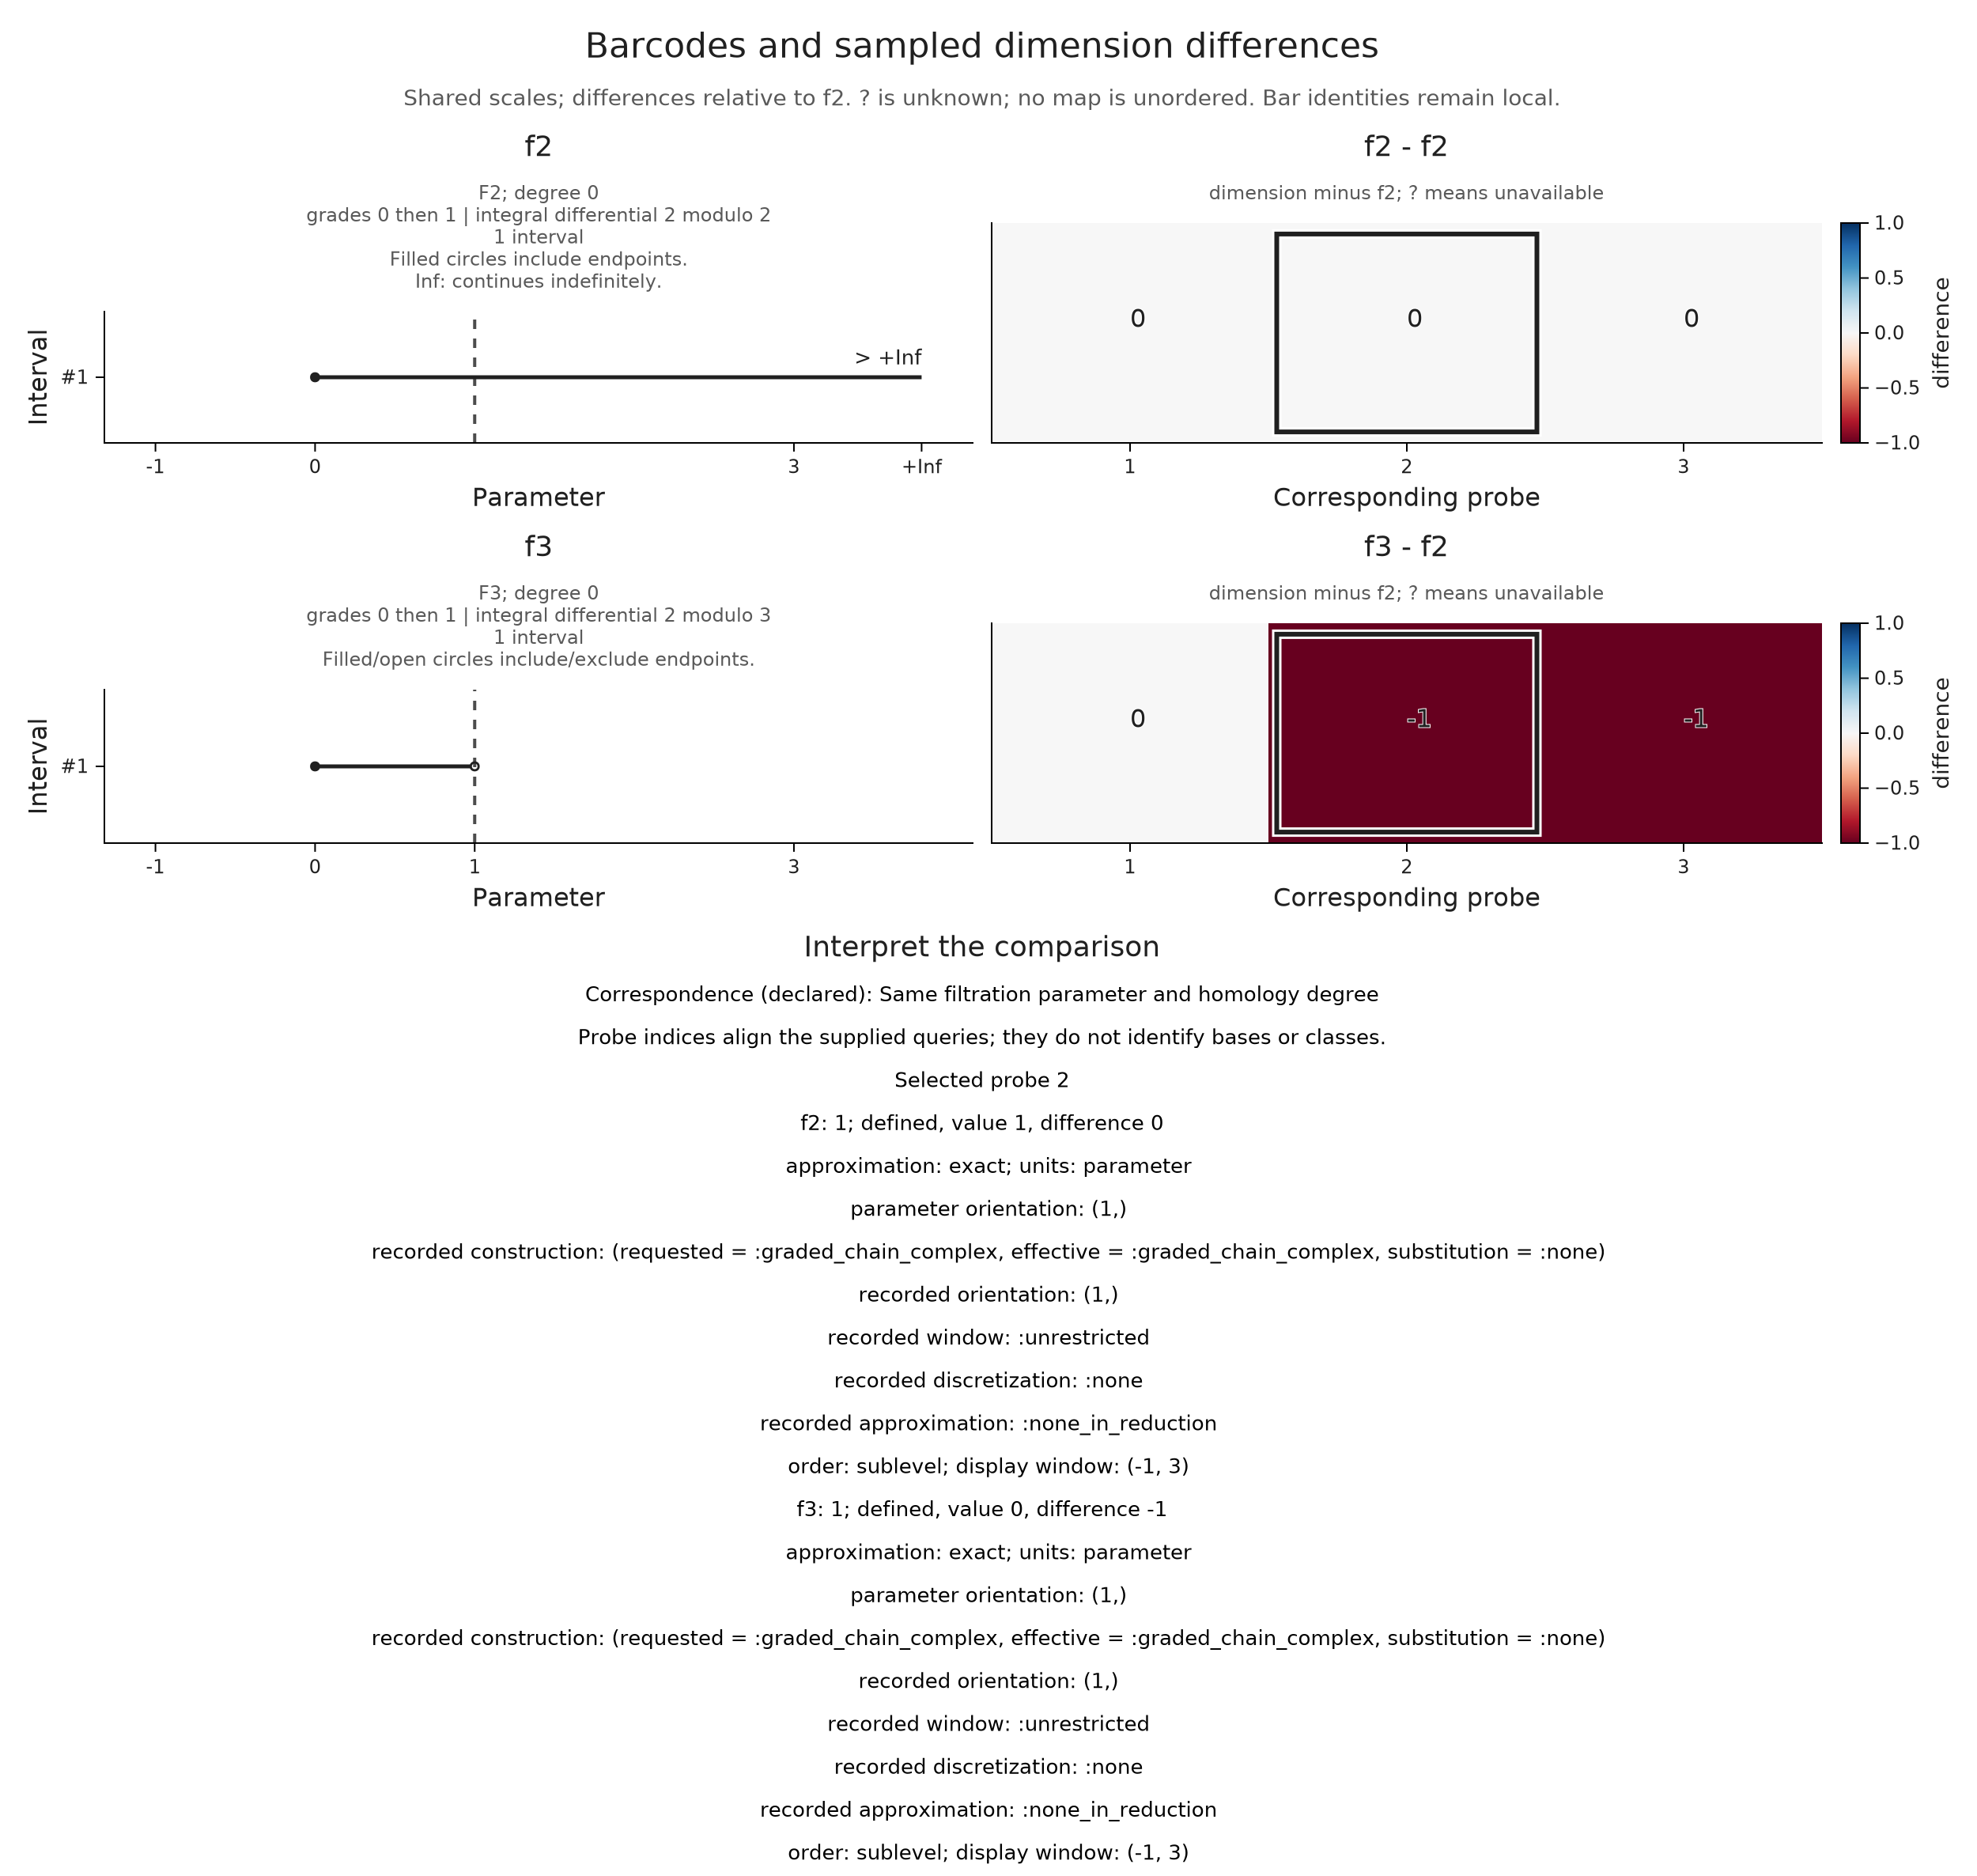

In [9]:
filtered_complex = OP.DataTypes.GradedComplex([[1],[2]], [sparse(reshape([2],1,1))], [(0,),(1,)])
diagram2 = OP.persistence_diagram(filtered_complex; field=F2)
diagram3 = OP.persistence_diagram(filtered_complex; field=F3)
bars = OP.compare_visuals((
    f2=OP.ComparisonCase(diagram2; degree=0, filtration="grades 0 then 1", construction="integral differential 2 modulo 2", approximation="exact"),
    f3=OP.ComparisonCase(diagram3; degree=0, filtration="grades 0 then 1", construction="integral differential 2 modulo 3", approximation="exact"));
    parameters=[0,1,2], window=(-1,3), correspondence="Same filtration parameter and homology degree")
OP.visualize(bars; view=:barcode, probe=2)

Barcode rows have identities only within their own result. Matching row numbers, shared colors, or a zero dimension difference do not match classes. Use the [distance-witness recipe](distance_witness.ipynb) when the question concerns a computed interval assignment.

Different homology degrees can share a parameter axis without claiming to be the same vector space. Over $\mathbf F_2$, our degree-one generator creates a class at 1. Compare the two degrees and explain why their dimension difference becomes zero there, even though the classes are different.

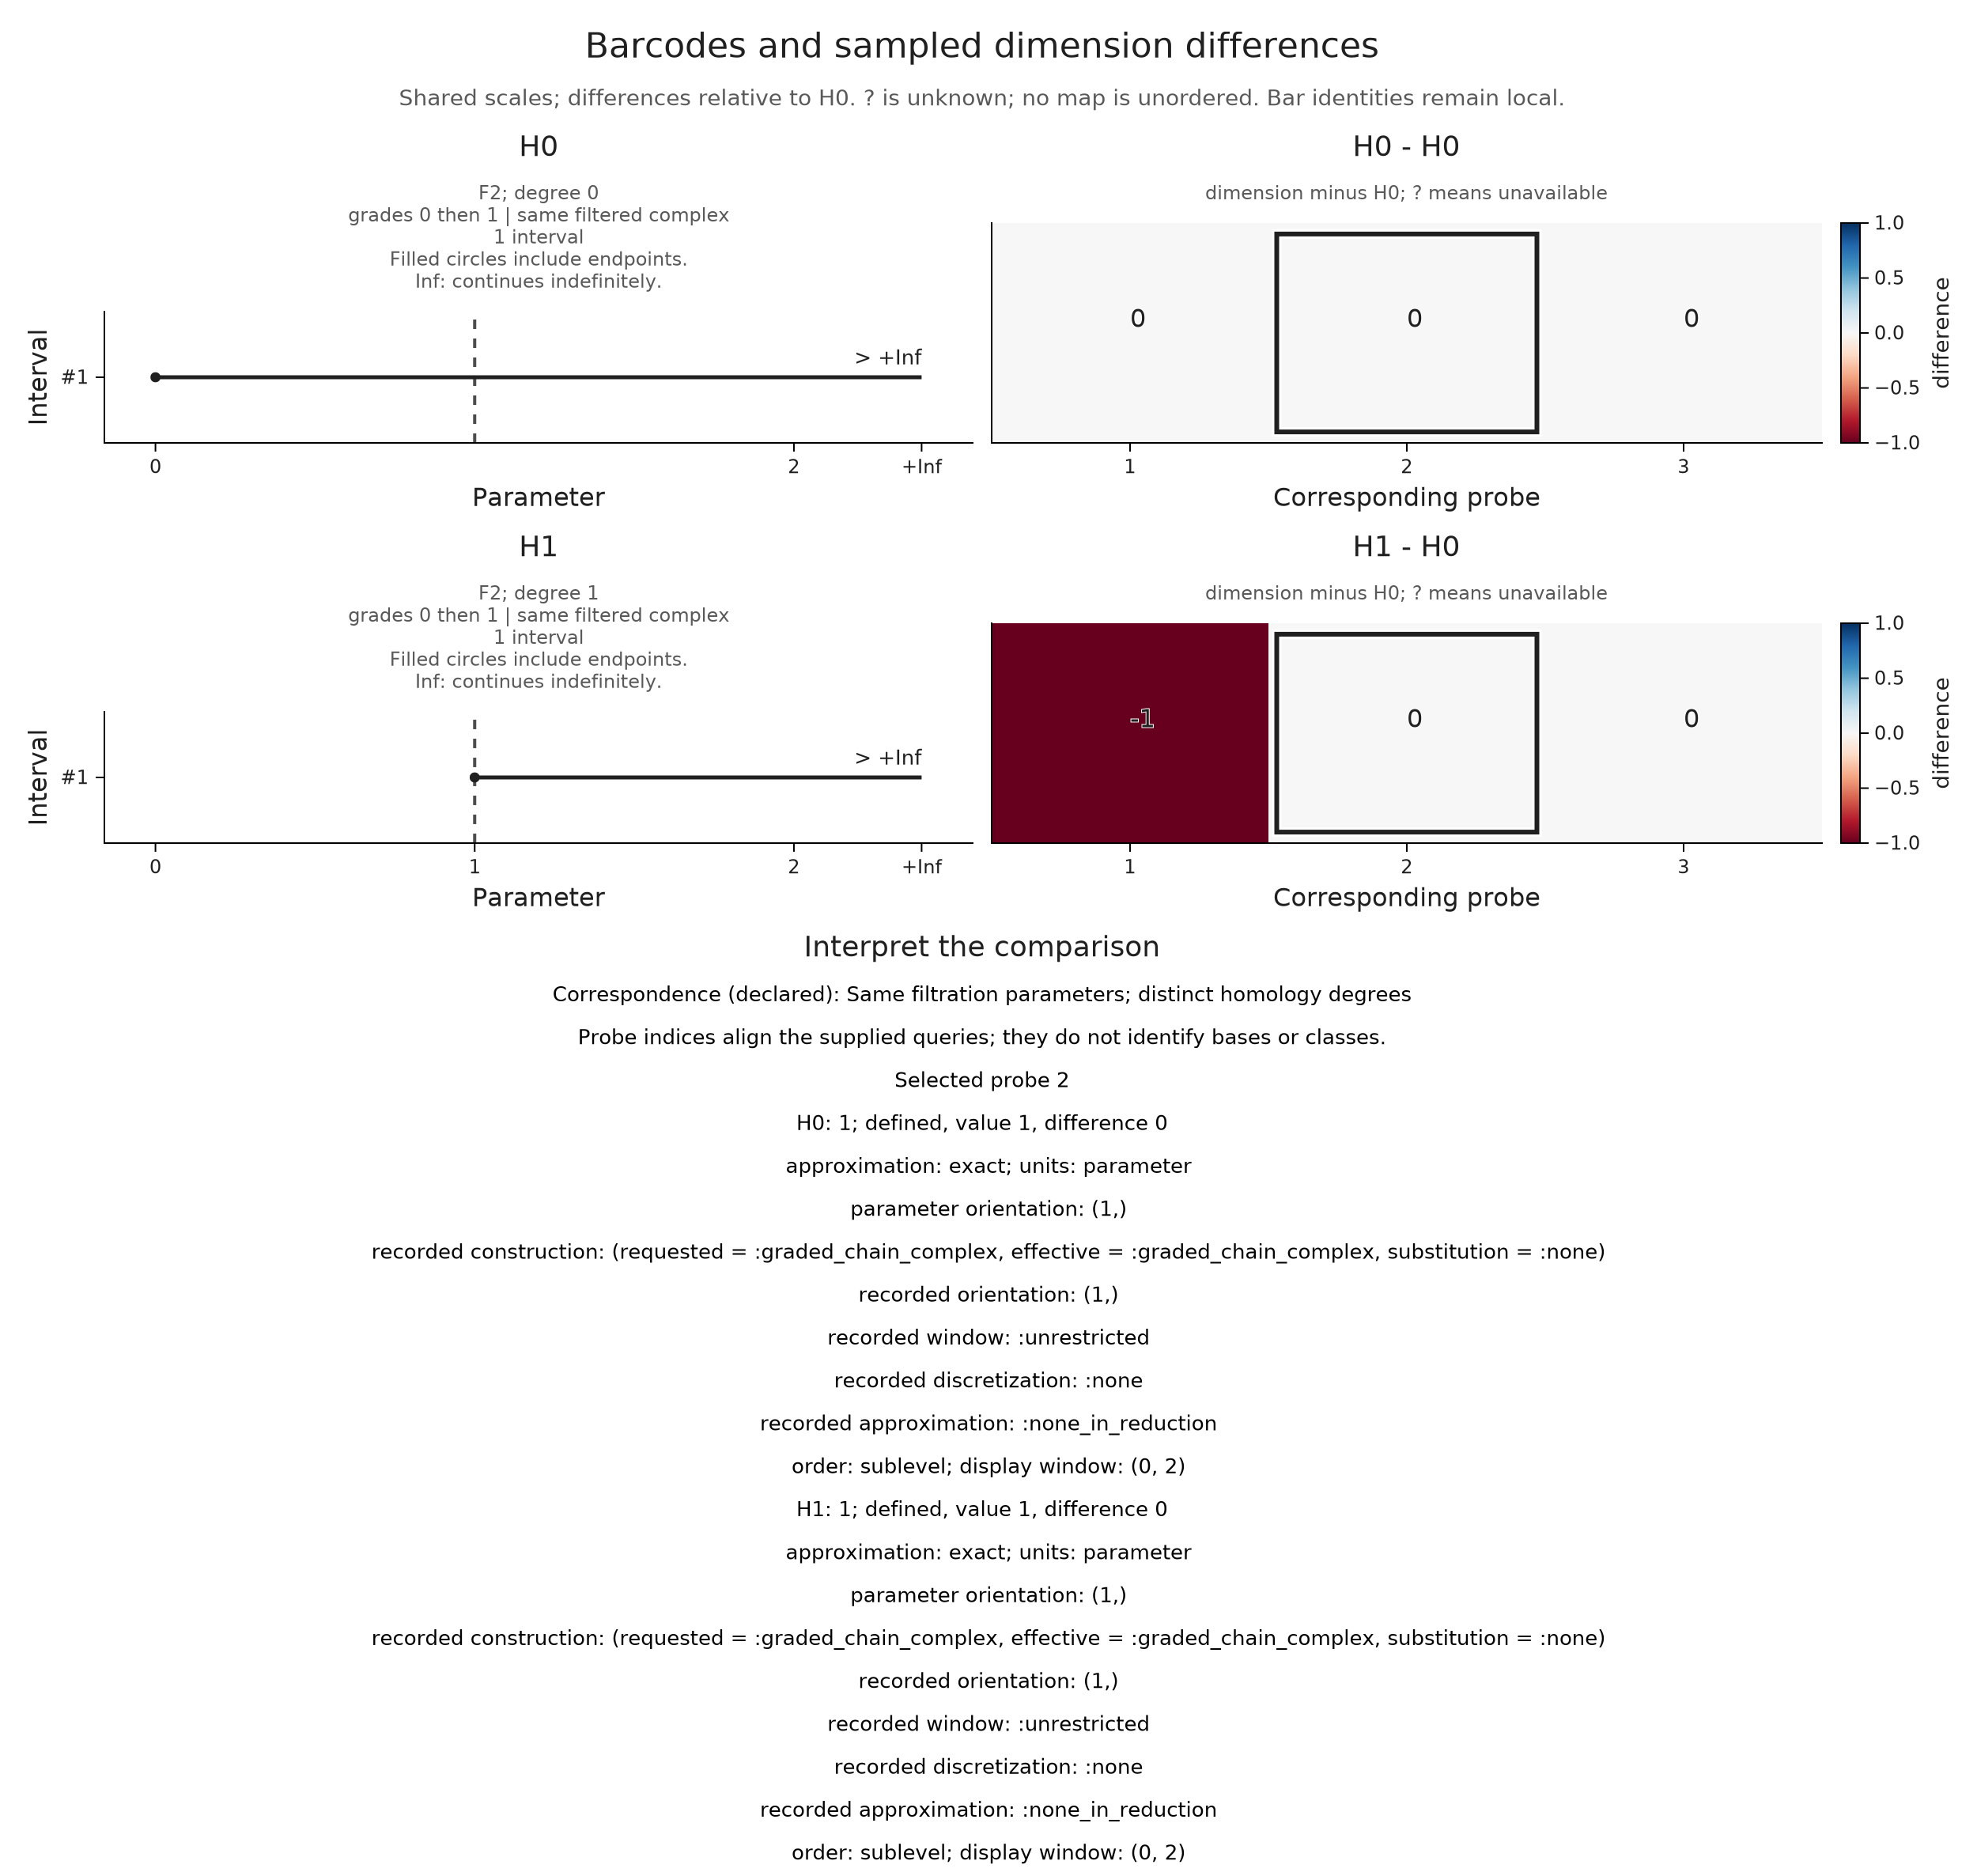

In [10]:
degrees = OP.compare_visuals((
    H0=OP.ComparisonCase(diagram2; degree=0, filtration="grades 0 then 1", construction="same filtered complex", approximation="exact"),
    H1=OP.ComparisonCase(diagram2; degree=1, filtration="grades 0 then 1", construction="same filtered complex", approximation="exact"));
    parameters=[0,1,2], correspondence="Same filtration parameters; distinct homology degrees")
OP.visualize(degrees; view=:barcode, probe=2)

## Keep numerical rank visible

Exact field algebra and floating-point rank answer different computational questions. For $\operatorname{diag}(1,0.0008)$, a numerical absolute tolerance of 0.001 discards the small direction, while the rational matrix has exact rank 2.

The rank readout also evaluates half and double the declared tolerances. A change flags sensitivity of this calculation. Agreement among those three choices is **not** an error bound or an exact-rank certificate.

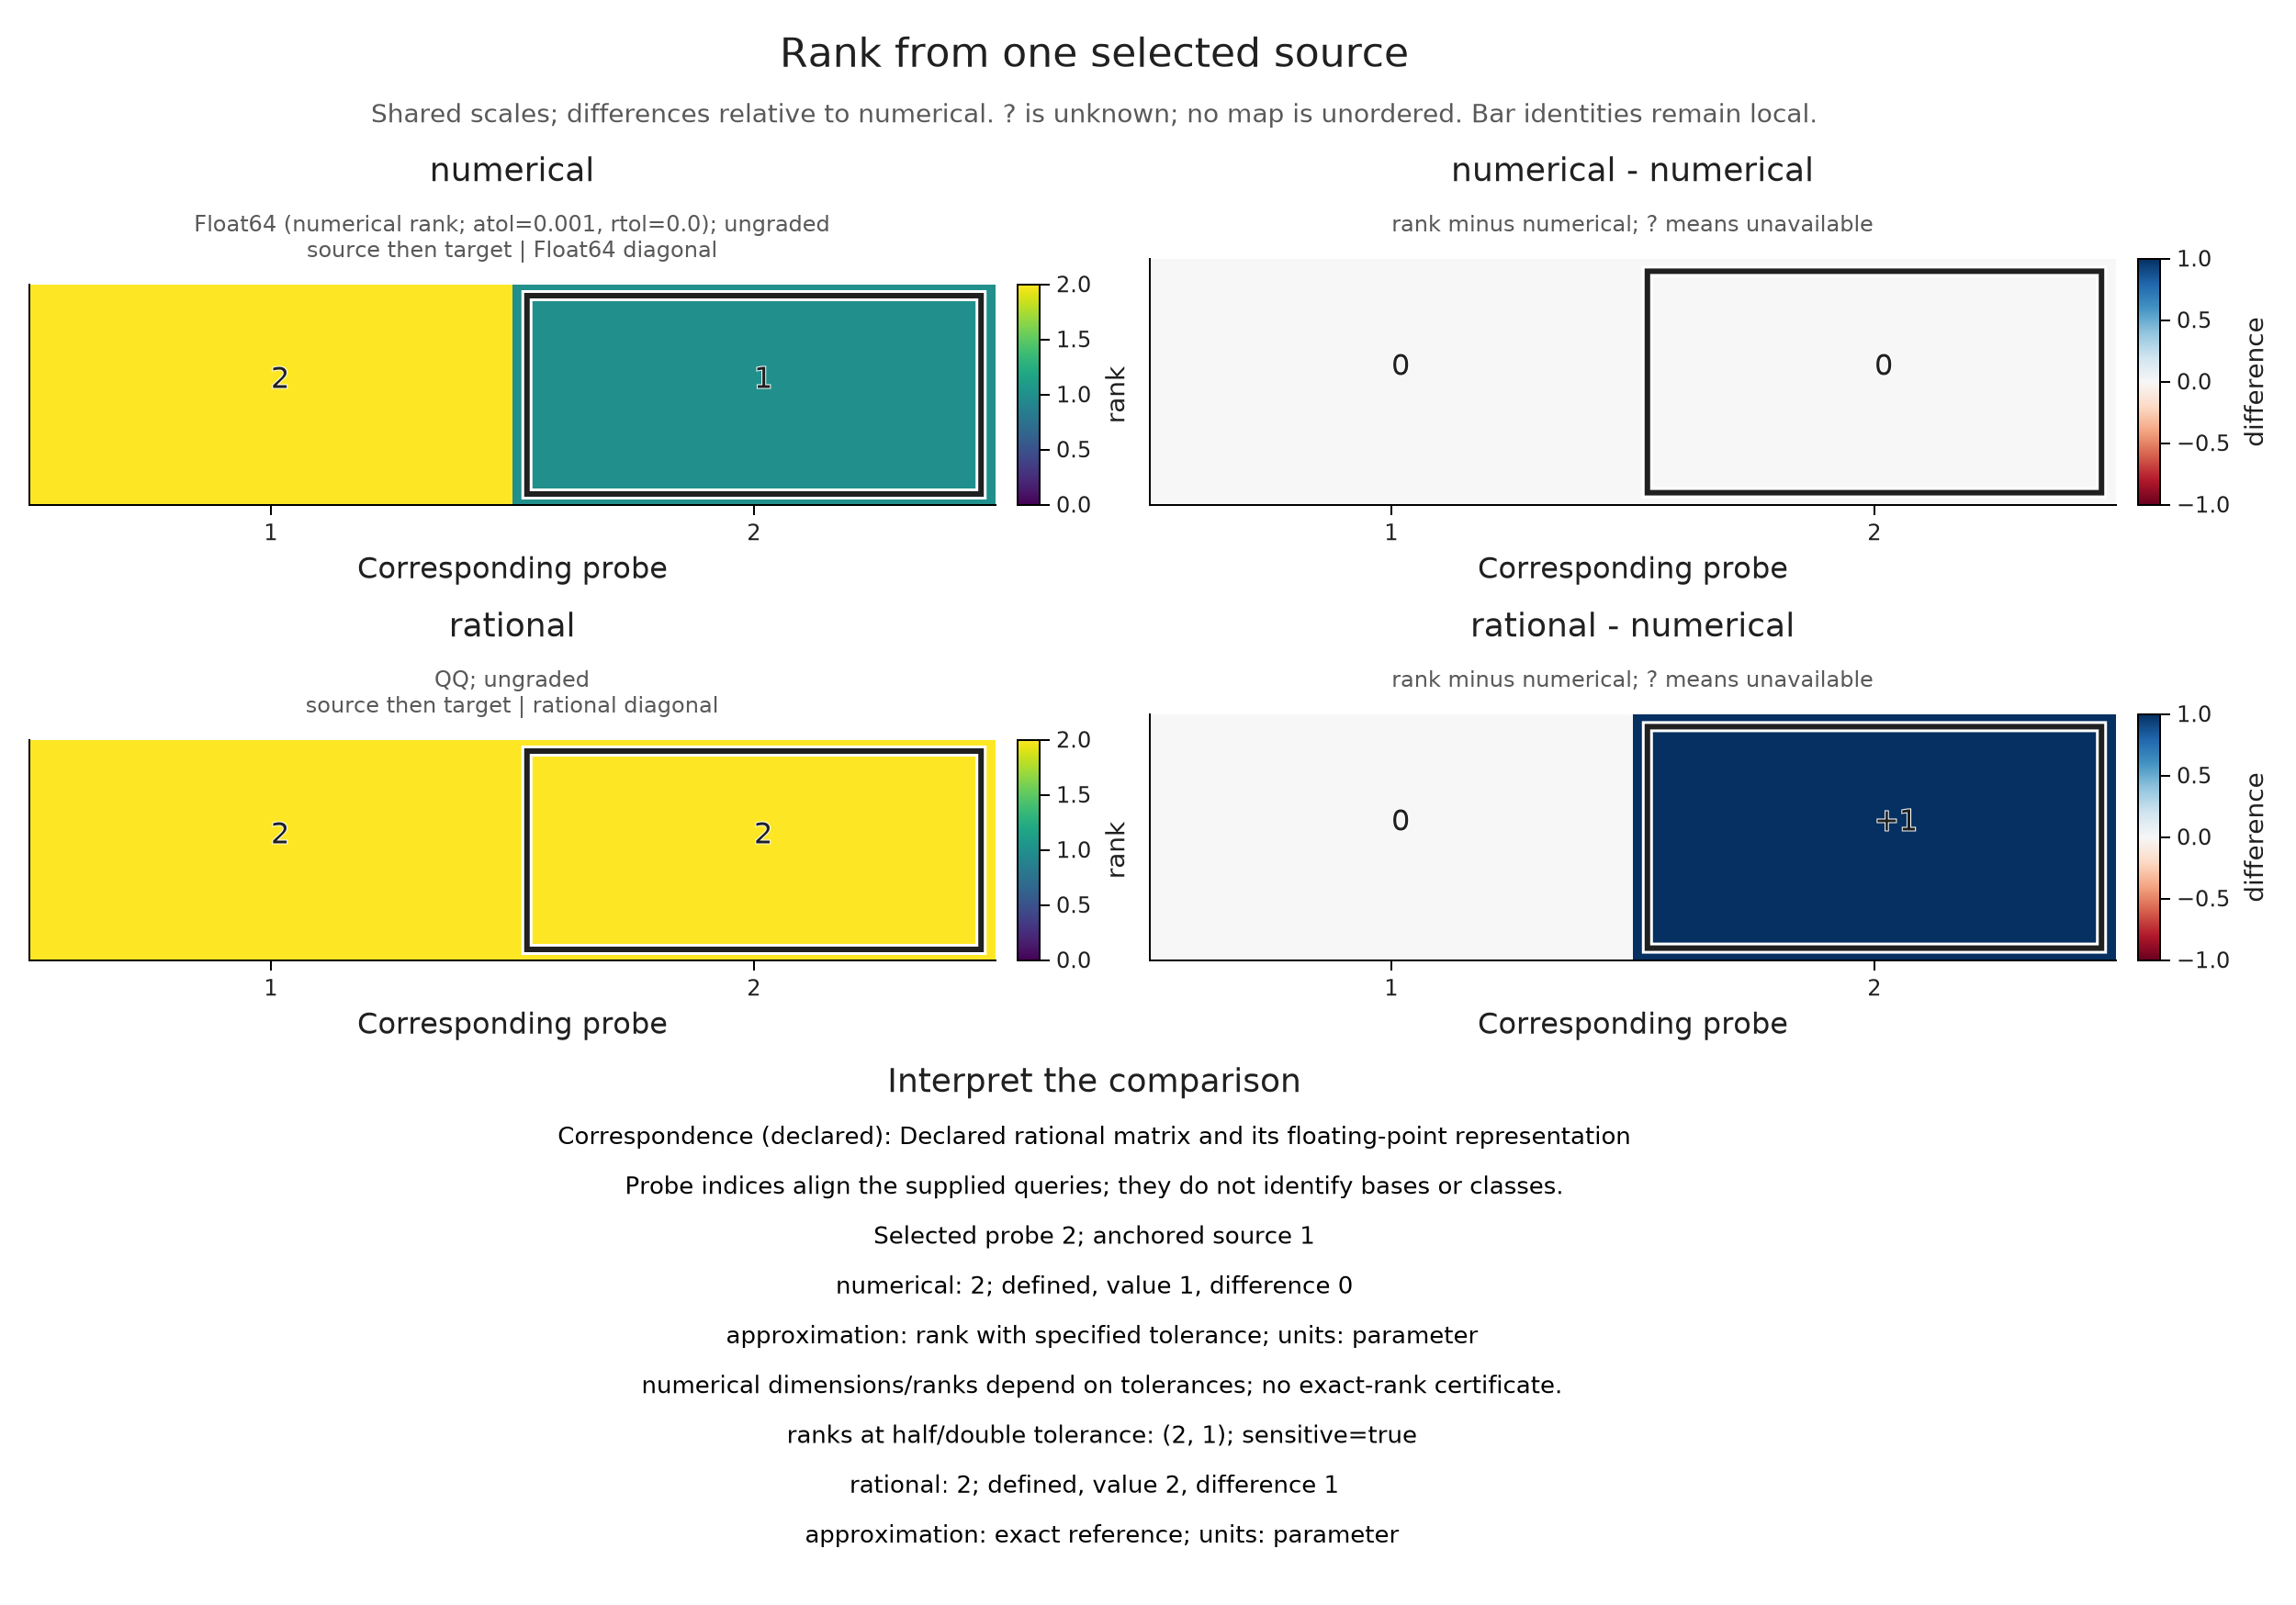

In [11]:
real_field = OP.CoreModules.RealField(Float64; atol=0.001, rtol=0.0)
numerical = OP.Advanced.PModule{Float64}(P, [2,2], Dict((1,2)=>[1.0 0; 0 0.0008]); field=real_field)
rational = OP.Advanced.PModule{OP.QQ}(P, [2,2], Dict((1,2)=>OP.QQ[1 0; 0 8//10000]))
tolerances = OP.compare_visuals((
    numerical=OP.ComparisonCase(numerical; filtration="source then target", construction="Float64 diagonal", approximation="rank with specified tolerance"),
    rational=OP.ComparisonCase(rational; filtration="source then target", construction="rational diagonal", approximation="exact reference"));
    vertices=(numerical=[1,2], rational=[1,2]), correspondence="Declared rational matrix and its floating-point representation")
OP.visualize(tolerances; view=:rank, probe=2)

## Explore linked selections

With WGLMakie loaded, the same comparison opens a live inspector:

```julia
import WGLMakie
session = OP.inspection_session(fields)
OP.visualize(session; backend=:wglmakie)
```

Click a value or difference strip to select a probe. **Anchored ranks** changes the question; the source field chooses its anchor. **Baseline case** changes the subtraction, and **Inspect selected matrices** requests the actual selected maps. Hover only reads retained values. An unordered pair displays “no map”; it is not a zero-rank map. A second `visualize(session)` opens another linked view. Close the inspector when finished; its final static snapshot remains available.

Queries preserve exact parameter values even though drawing uses floating-point coordinates. Only the requested anchor row is computed; there is no hidden all-pairs rank table. Changing the selected target or baseline reuses that row. For a lazy encoding, the first nontrivial map also materializes the finite module. Keep compared inputs read-only and rebuild the comparison after changing them.

## Compare samples through named features

So far a comparison aligned queries inside a few results. A collection changes the unit of comparison: each row is now a **sample**, and a column describes one mathematical feature of that sample. The row identity must survive a change of view.

Consider three supplied interval modules. Each has one half-open interval: A lives on $[0,2)$, B on $[0,3)$, and C on $[2,4)$. We record its lifetime and its dimension at parameter 1. Their feature rows are therefore $(2,1)$, $(3,1)$ and $(2,0)$. A and C have equal lifetimes but answer the parameter query differently. This is a small example of why the feature's definition matters as much as its value.

`Featurizers.FeatureSet` is the row-by-feature container returned by batch featurization. Here we supply the hand-calculated values so their meaning is visible before plotting. The two columns have different meanings; we apply no normalization.

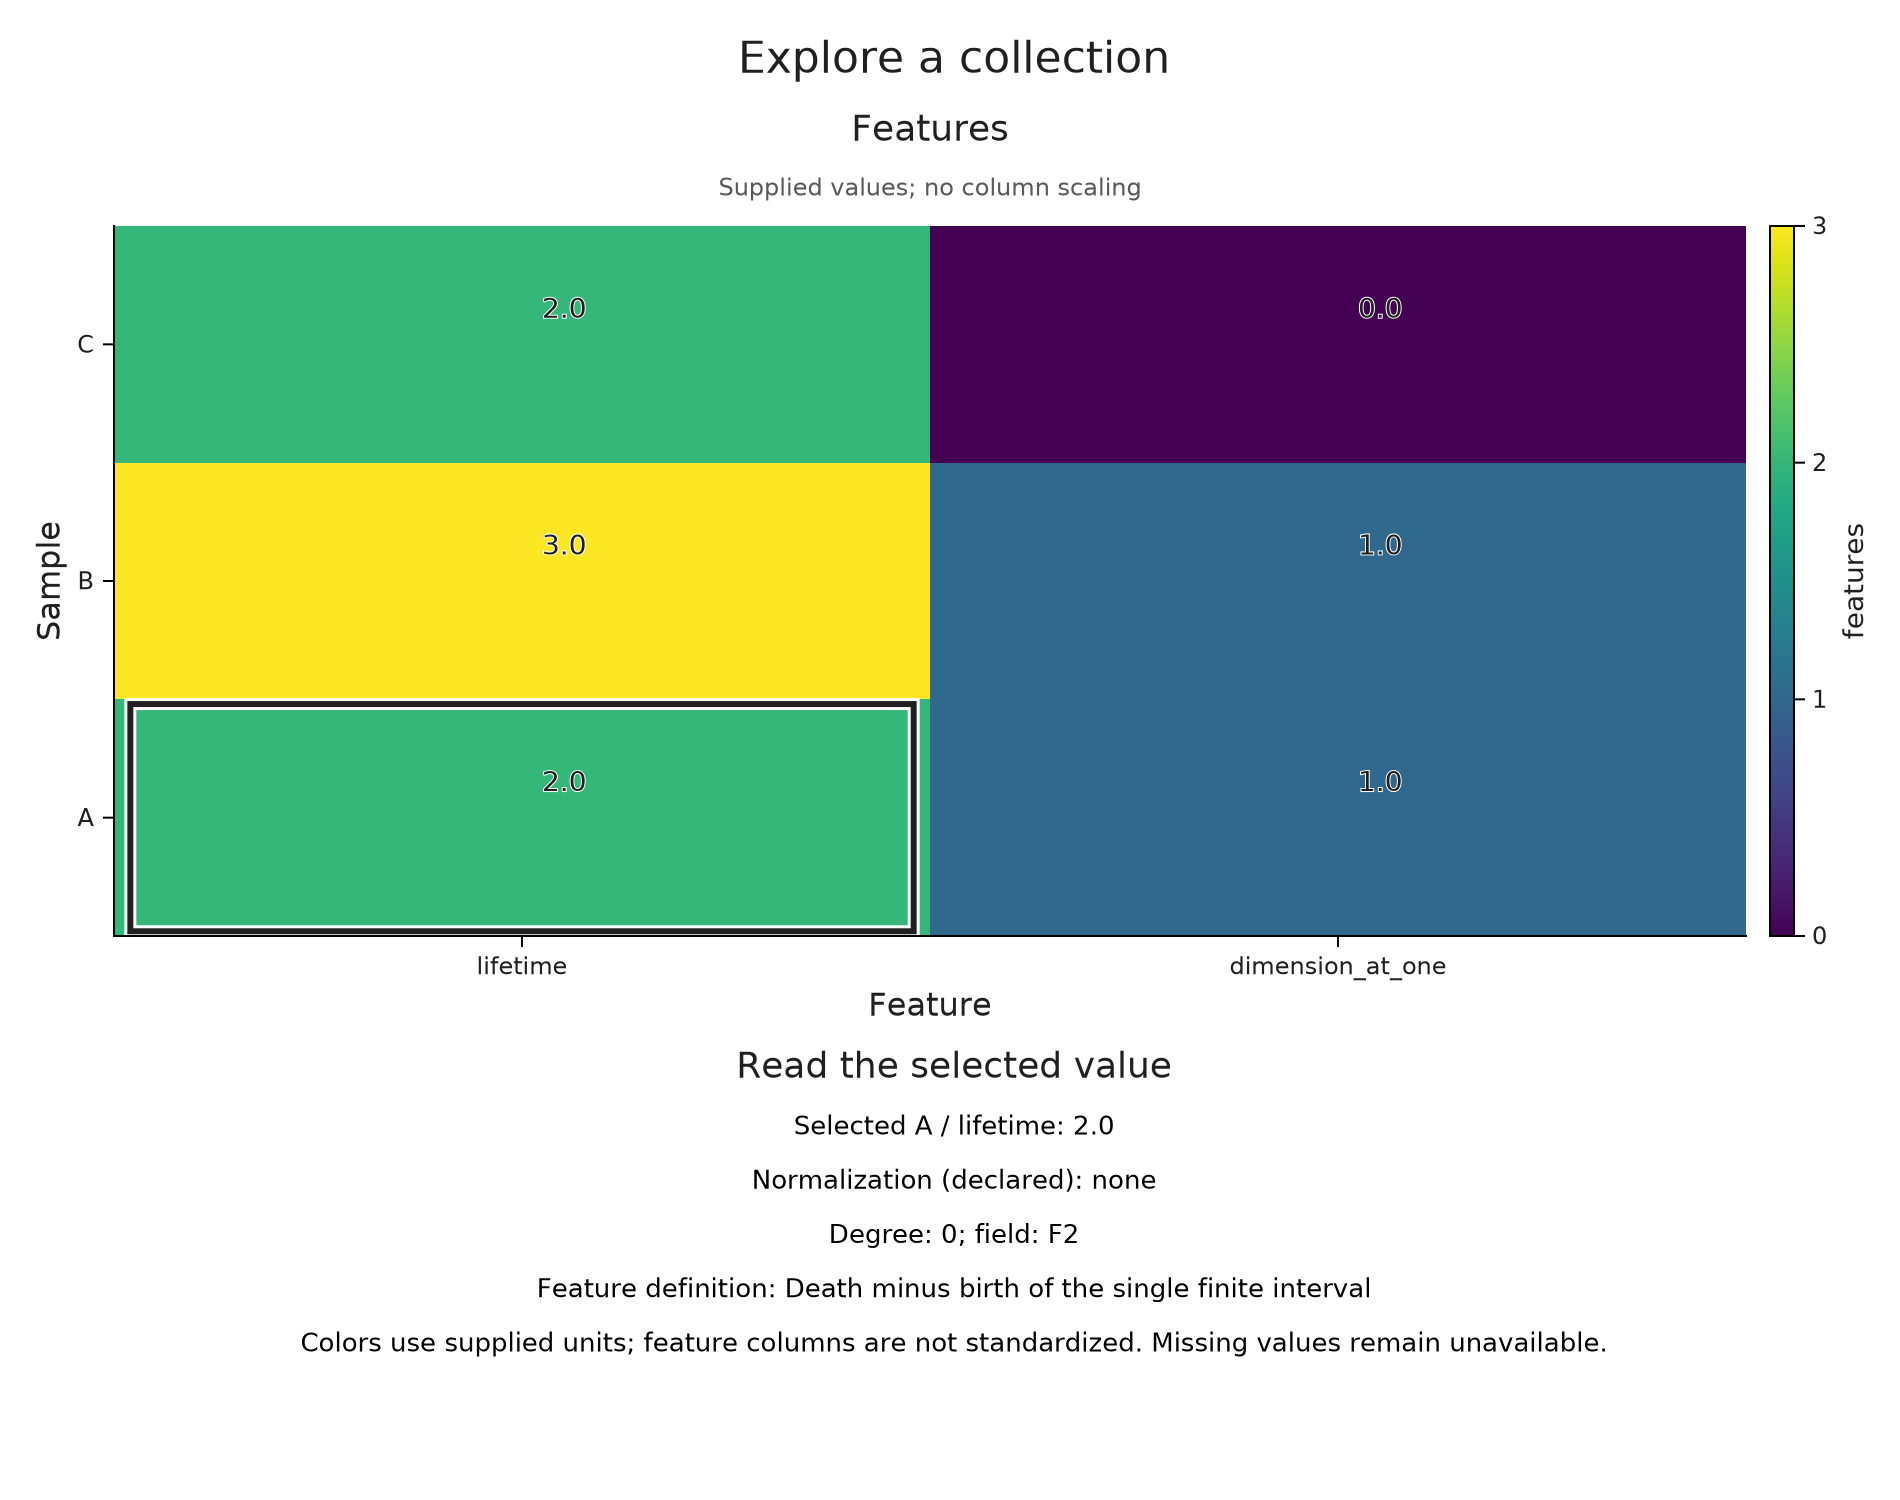

In [12]:
bars = [[(0.,2.)], [(0.,3.)], [(2.,4.)]]
features = OP.Featurizers.FeatureSet(
    [2. 1.; 3. 1.; 2. 0.], [:lifetime, :dimension_at_one], ["A", "B", "C"],
    (;interval_convention="[birth, death)", parameter=1, normalization="none"))
definitions = ["Death minus birth of the single finite interval",
               "Dimension of the interval module at parameter 1"]
collection = OP.visual_collection(features; definitions, degree=0, field="F2")
OP.visualize(collection)

The labels keep row and column meanings visible. The color scale covers the **supplied numbers**; it neither standardizes the columns nor asserts that a unit of lifetime is comparable to a unit of dimension. Select a feature to read its definition. If you standardize features elsewhere, record the transform in `normalization`, including how its parameters were fitted.

### A distance is a different object

For these intervals the bottleneck distances are $d(A,B)=1$, $d(A,C)=1$, and $d(B,C)=3/2$. The latter two optima use the diagonal: deleting the bars costs half their lifetimes. We supply this small distance table explicitly. Preparing a collection never computes all pairs.

We also retain each sample's barcode view. Selection can then return from a number to the invariant that produced it. A `source` view can be supplied in the same way when the sample has a point cloud, graph or image; these abstract interval modules have no such source data.

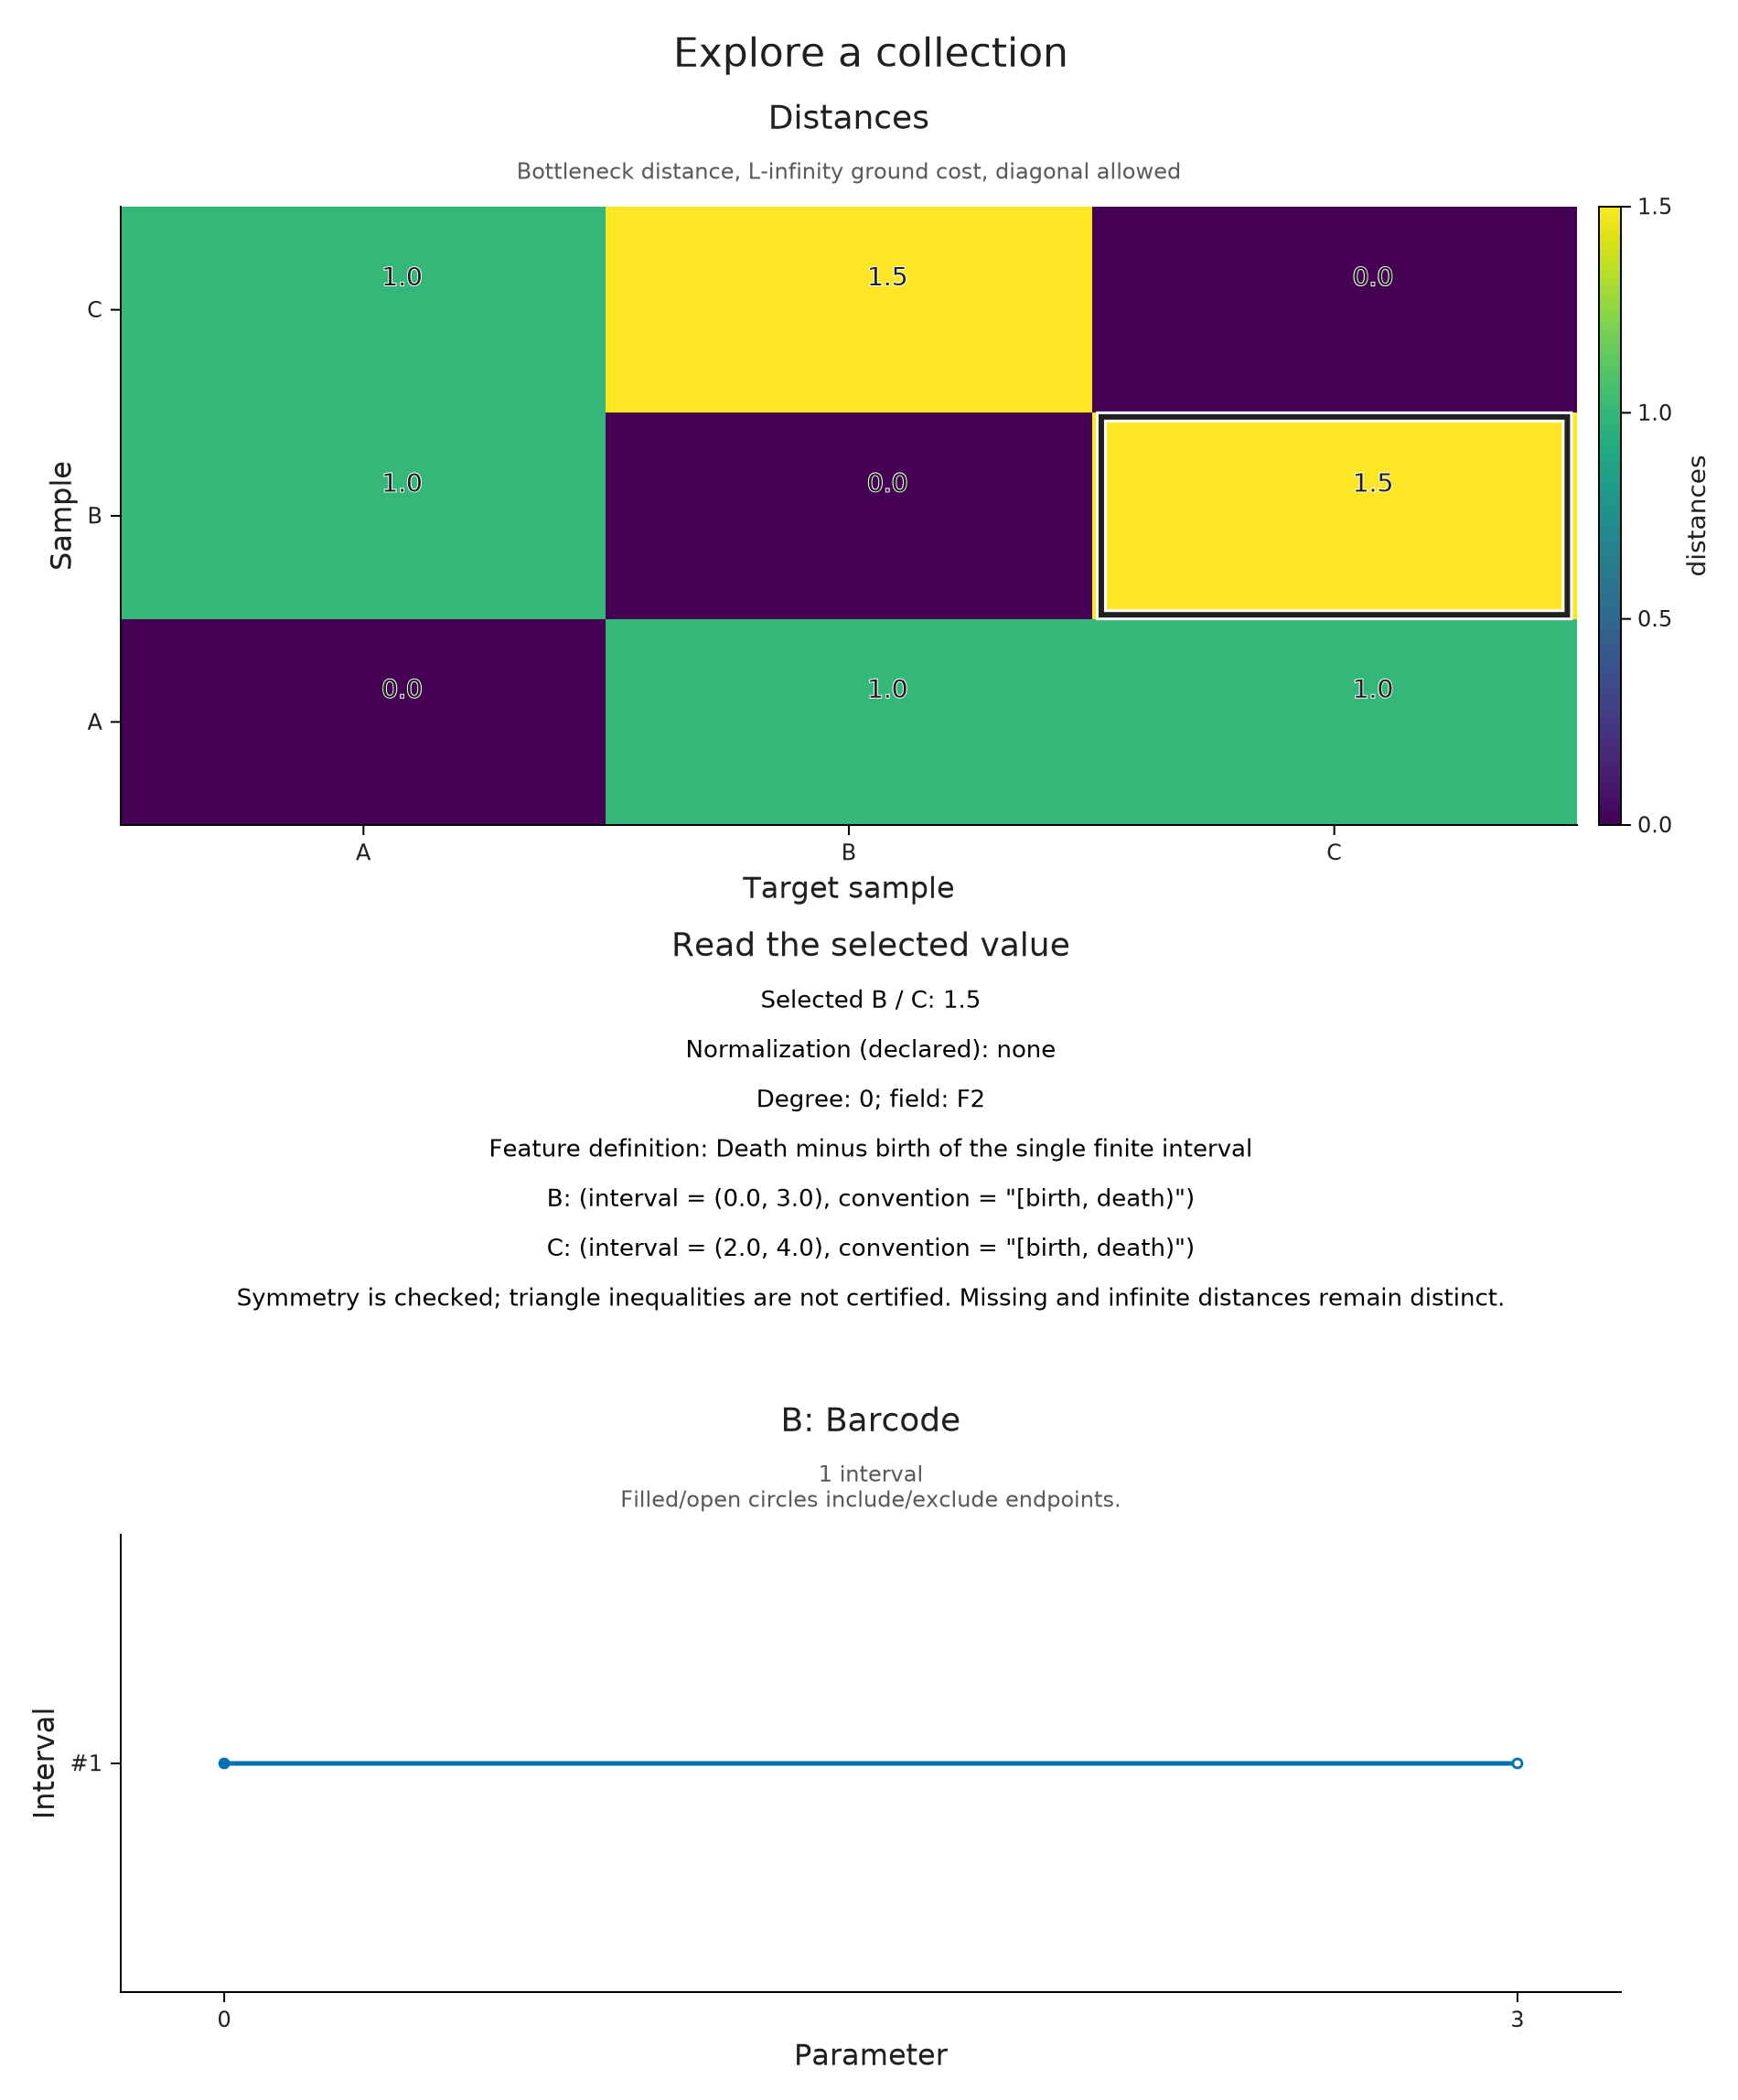

In [13]:
sample_views = [(;object=bar, invariant=OP.Advanced.visual_spec(bar),
                  metadata=(interval=only(bar), convention="[birth, death)")) for bar in bars]
distances = [0. 1. 1.; 1. 0. 1.5; 1. 1.5 0.]
witness_AB = OP.bottleneck_matching(bars[1], bars[2])
collection = OP.visual_collection(features; definitions, distances,
    distance_semantics="Bottleneck distance, L-infinity ground cost, diagonal allowed",
    degree=0, field="F2", samples=sample_views,
    witnesses=Dict(("A", "B")=>witness_AB))
OP.visualize(collection; view=:distances, sample="B", target="C")

A symmetric zero-diagonal table is not automatically a metric: the constructor checks shape, signs and symmetry, but does not certify the triangle inequality. `missing` means an unavailable pair; `Inf` means an infinite supplied distance. Neither is replaced by zero.

A **kernel** is a similarity table. Its diagonal generally is not zero, and it may contain negative entries. Pass it as `kernel`, with `kernel_semantics`, rather than presenting it as a distance. Positive semidefiniteness is not certified by the viewer.


The following dot-product kernel uses our two unnormalized columns. That choice depends on their units and scaling; it is an explicit modelling choice, not a default interpretation of the feature heatmap.

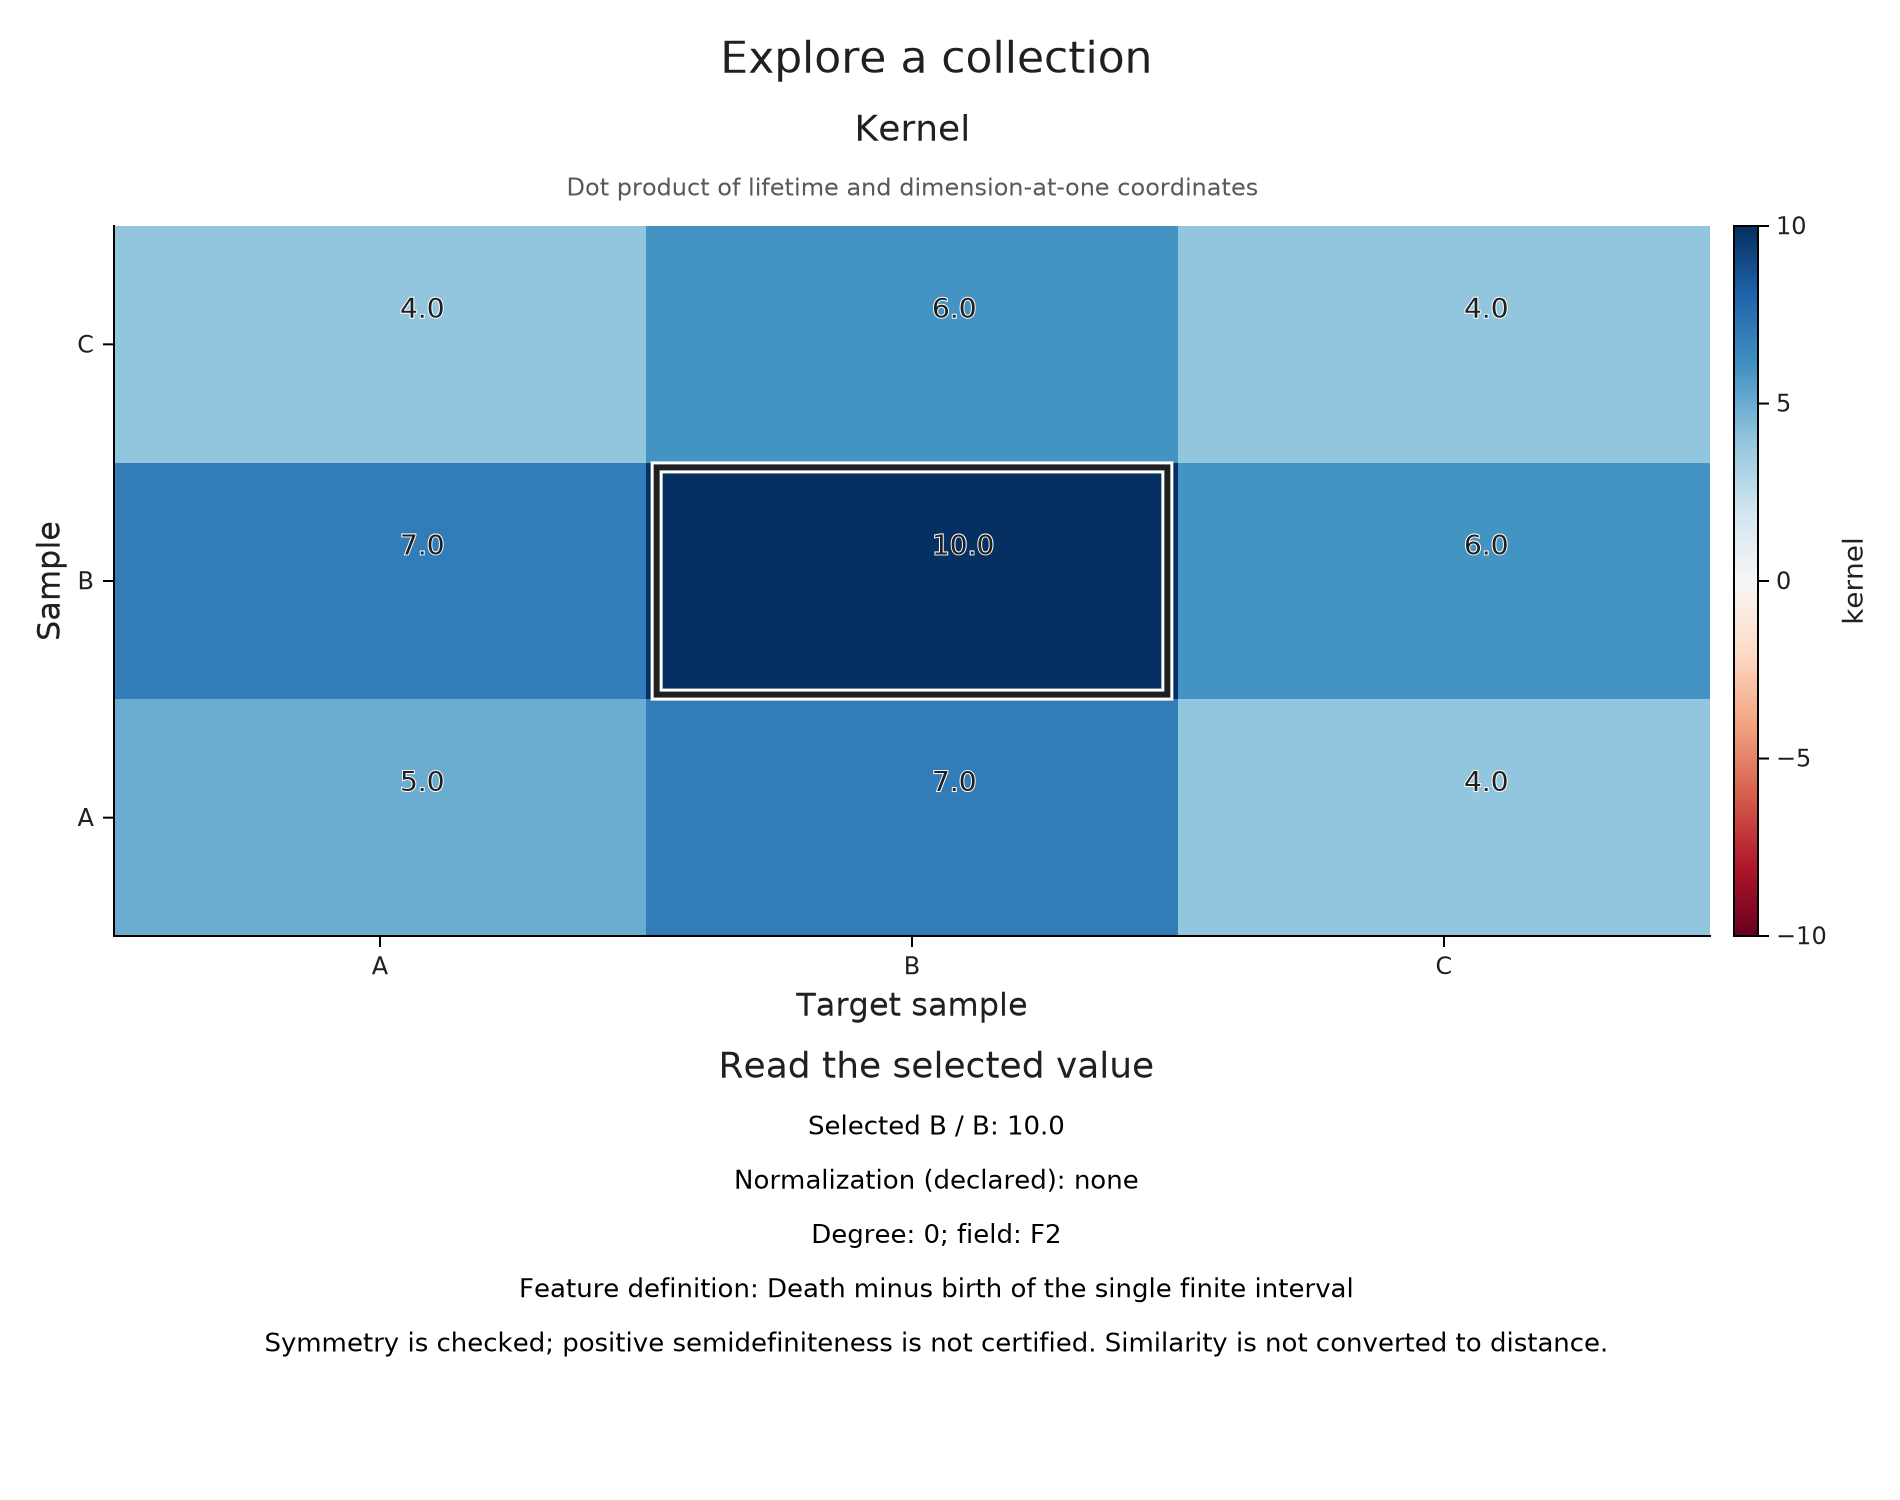

In [14]:
similarities = [5. 7. 4.; 7. 10. 6.; 4. 6. 4.]
kernel_collection = OP.visual_collection(features; definitions, kernel=similarities,
    kernel_semantics="Dot product of lifetime and dimension-at-one coordinates",
    degree=0, field="F2")
OP.visualize(kernel_collection; view=:kernel, sample="B", target="B")

### An embedding helps us look, not prove

An ecosystem tool may turn feature vectors or distances into two plotting coordinates. `visual_collection` accepts those coordinates together with the method, settings and seed. It does not choose or run the embedding algorithm. Here we use the two feature coordinates themselves, a deterministic display with no fitted transform. Its Euclidean separations are not our bottleneck distances: B and C lie $\sqrt{2}$ apart in this picture but have bottleneck distance $3/2$.

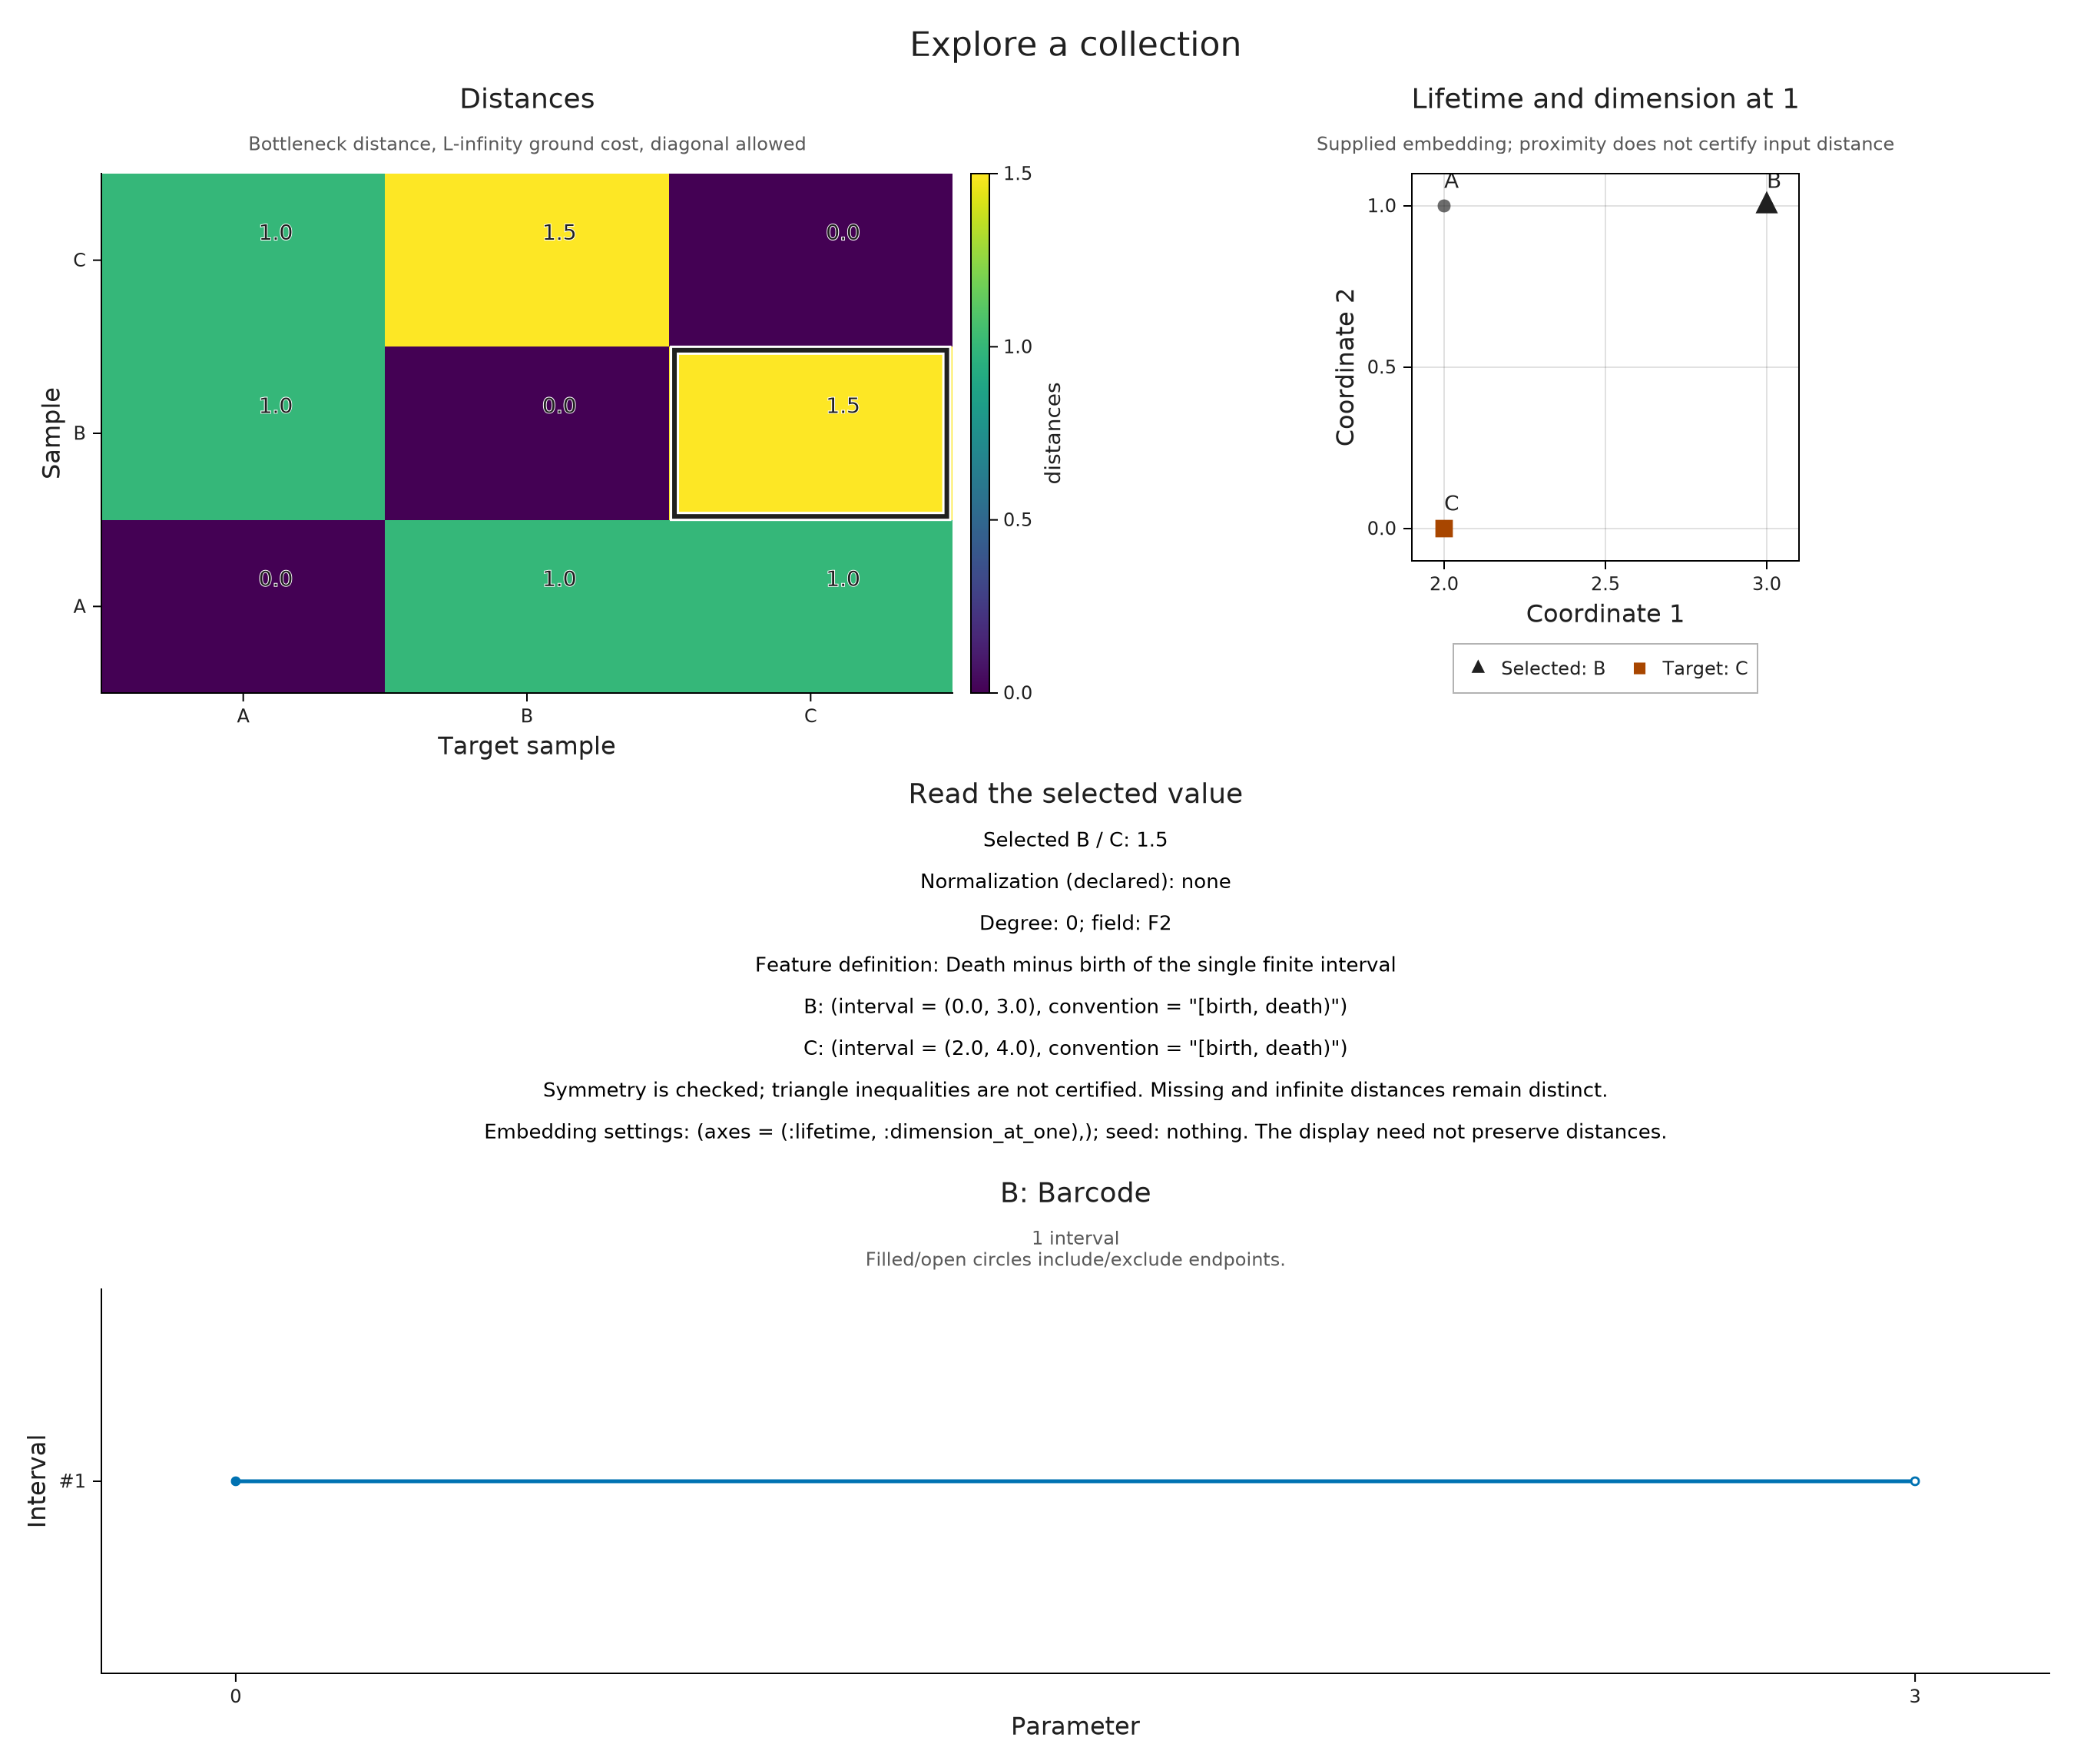

In [15]:
embedded = OP.visual_collection(features; definitions, distances,
    distance_semantics="Bottleneck distance, L-infinity ground cost, diagonal allowed",
    degree=0, field="F2", samples=sample_views,
    embedding=(coordinates=OP.Featurizers.feature_matrix(features),
               method="Lifetime and dimension at 1", settings=(axes=(:lifetime,:dimension_at_one),), seed=nothing))
OP.visualize(embedded; view=:distances, sample="B", target="C")

### Open the selected pair

A collection inspector links the table, embedding and sample views. `sample` and `target` use the same stable IDs in every view. Feature selection also exposes its mathematical definition. Hover reads prepared values; it performs no invariant or distance computation.

For an already supplied witness, `collection_matching` opens the [matching-witness explorer](distance_witness.ipynb). A witness belongs to an **ordered pair** because its assignments distinguish source from target. Its mathematical context must agree with the interpretation you intend; the viewer does not certify agreement with an arbitrary supplied matrix.

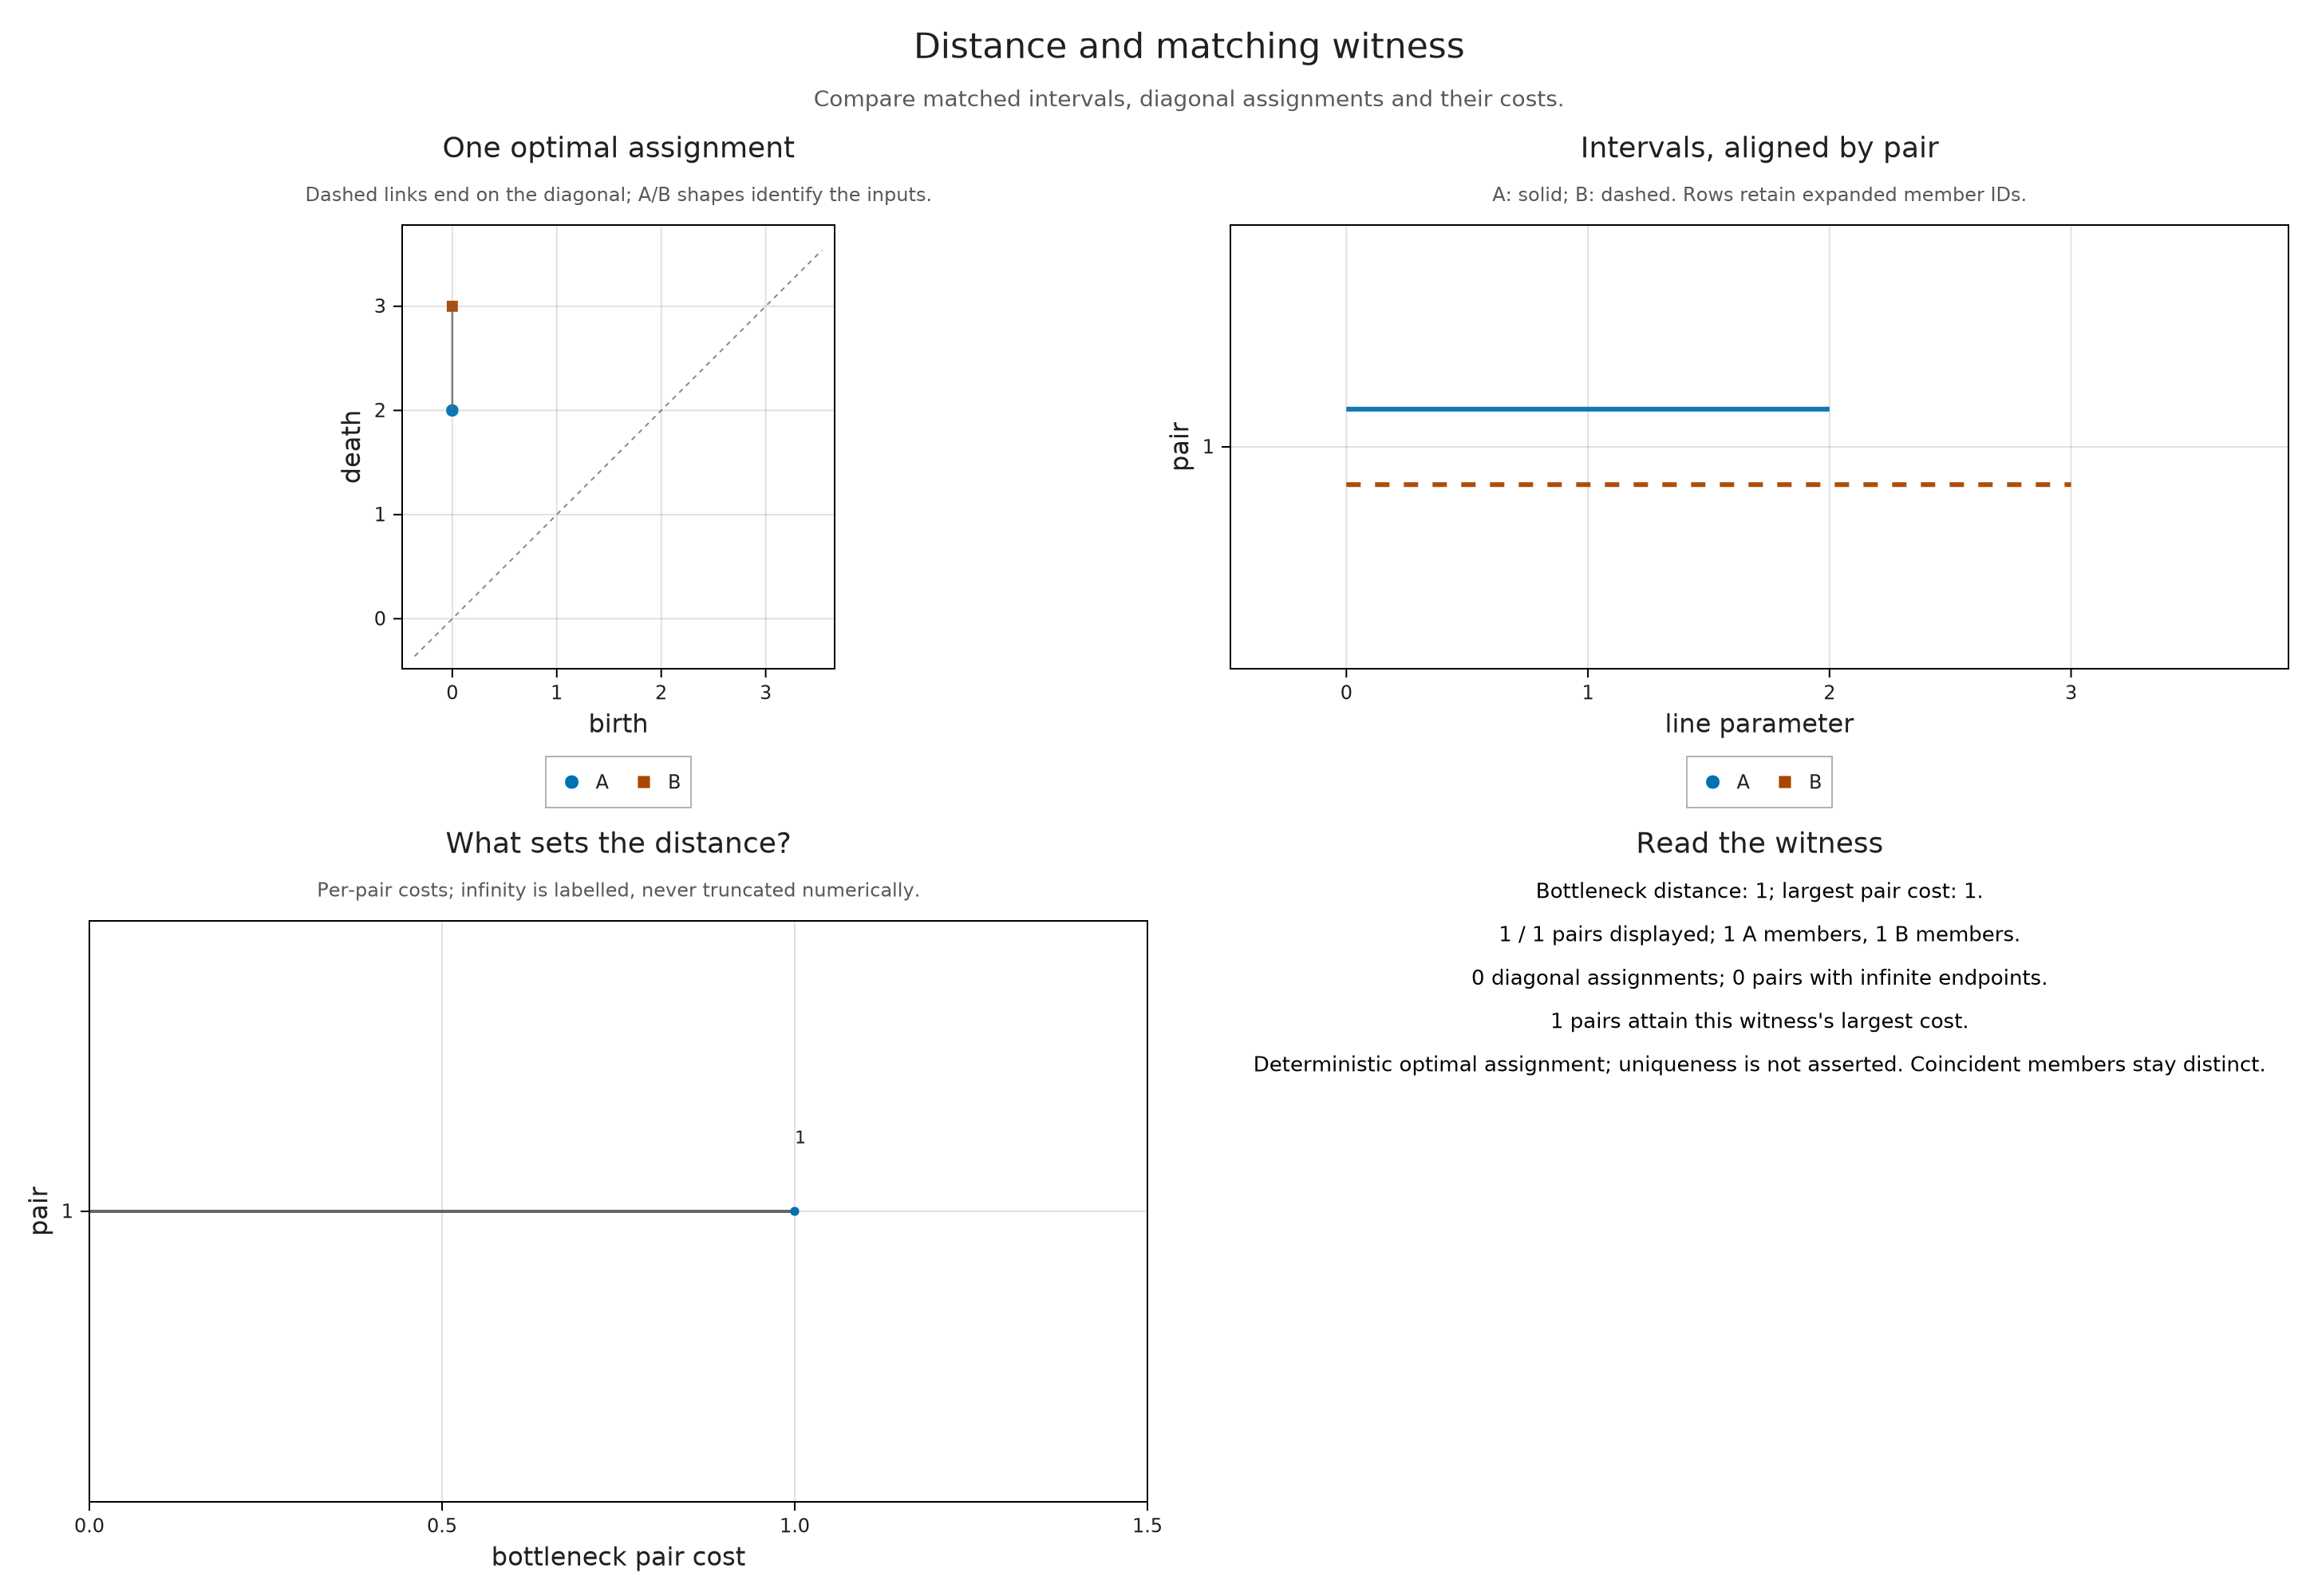

In [16]:
collection_session = OP.inspection_session(collection; view=:distances)
pair_session = OP.collection_matching(collection_session)
@assert OP.Advanced.inspection_snapshot(pair_session).metadata.matching_records !== nothing
OP.visualize(OP.Advanced.inspection_snapshot(pair_session))

With WGLMakie loaded, `OP.visualize(collection_session)` opens the live controls. Clicking a matrix cell selects its row and column; clicking an embedded point selects its sample. The **Open supplied matching** button opens that pair's retained witness. Change the parent selection to close the embedded pair view. Separate Julia-created matching sessions remain independently usable.

To compute a pair that has no retained witness, request it explicitly.

This computes just B against C using their retained interval objects. For ordinary `PersistenceDiagram`s also supply `dim`; for encoded pairs supply the required finite-window options. The [API reference](../src/reference/visualization.md#collections-of-features-distances-and-kernels) gives the input and budget contracts. Computing a pair does not overwrite a supplied matrix or certify its other entries. Close independent sessions when finished.

In [17]:
OP.Advanced.select_inspection!(collection_session; sample="B", target="C")
pair_BC = OP.collection_matching(collection_session; compute=true)
selected_distance = OP.Advanced.inspection_summary(pair_BC).distance
@assert selected_distance == 1.5
selected_distance

1.5

In [18]:
OP.Advanced.close_inspection!(pair_BC)
OP.Advanced.close_inspection!(pair_session)
OP.Advanced.close_inspection!(collection_session);

CollectionInspectionSession(view=distances, closed=true)

## Optional: prepare a figure for sharing

The default views already include the context needed to interpret the numbers. Styling and export are independent of those calculations. This grayscale export uses the same prepared rank answer.

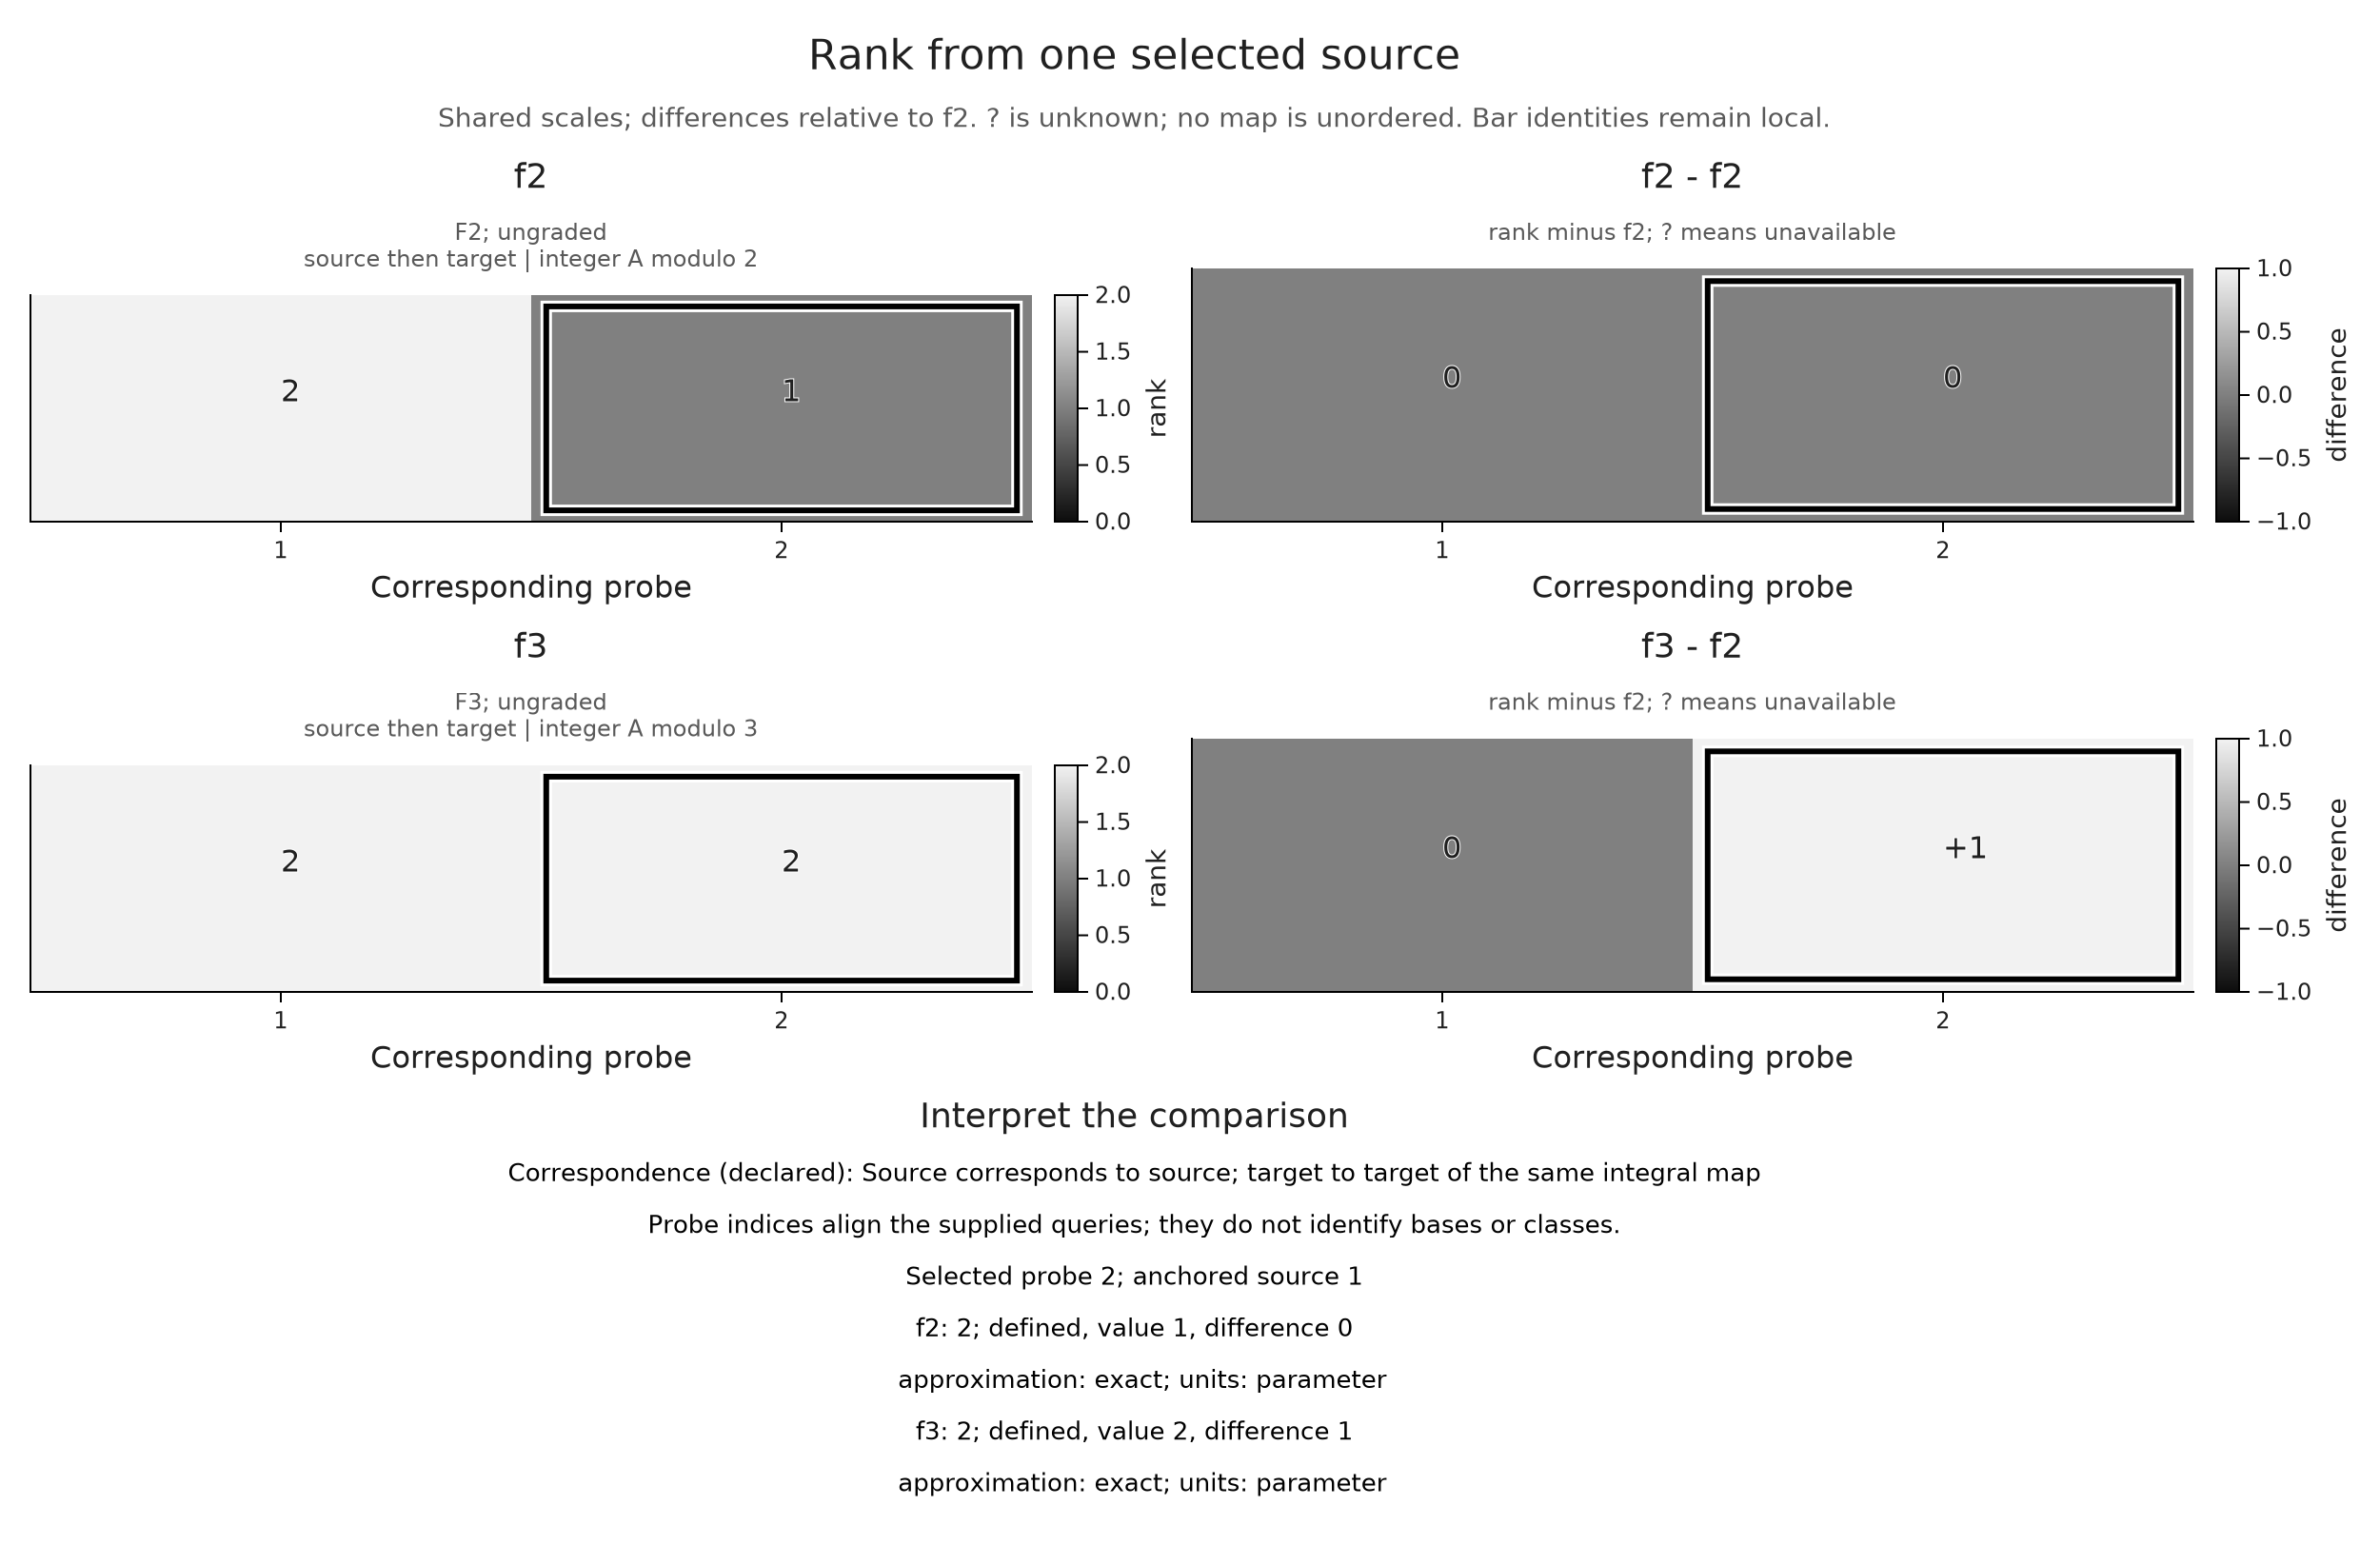

In [19]:
OP.visualize(rank_view; style=OP.VisualStyle(palette=:grayscale))

In [20]:
export_directory = mktempdir()
OP.save_visual(joinpath(export_directory, "field-ranks.svg"), rank_view);

"/tmp/jl_UOwMS2/field-ranks.svg"

You can now state which queries correspond and distinguish a change in an observable from a change in its coordinates. For a collection, you can also trace a selected number back to its feature definition, sample invariant or pair witness, while keeping table semantics separate from display geometry. For certified maps between finite descriptions, continue to [refining and transporting encoded modules](compare_encodings.ipynb). To combine these prepared panels with other mathematical views, use [composing mathematical figures](compose_figures.ipynb).